In [ ]:
pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm

In [87]:
pip install shap lime dice-ml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 42.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [64]:
!pip install -U selenium

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
# Set seeds
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#%% [markdown]
# ## 1. Configuration and Attack Mapping

#%%
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (46, 1), # (Features, Channels)
    'use_mock_data': False, # Set to False and provide path below for real data
    'dataset_path': '/kaggle/input/ciciot2023/CICIOT23',
    'second_dataset':"/kaggle/input/ton-iot-network-dataset/train_test_network.csv",
    "temperature":2.0,
    'ae_loss_weight': 0.1 
}

# --- Detailed Mapping Strategy (From User Request) ---

ATTACK_MAPPING = {
    # --- DoS: Seen vs Unseen ---
    'DoS-TCP_Flood': 'DoS_TCP_Flood',           # SEEN
    'DoS-SYN_Flood': 'DoS_SYN_Flood',           # SEEN
    'DoS-HTTP_Flood': 'DoS_HTTP_Flood',          # SEEN
    'DoS-UDP_Flood': 'DoS',    # UNSEEN (Emerging Variant)
    
    # --- DDoS: Seen vs Unseen ---
    'DDoS-TCP_Flood': 'DDoS',         # SEEN
    'DDoS-PSHACK_Flood': 'DDoS',      # SEEN
    'DDoS-SYN_Flood': 'DDoS',         # SEEN
    'DDoS-RSTFINFlood': 'DDoS',       # SEEN
    'DDoS-SynonymousIP_Flood': 'DDoS',# SEEN
    'DDoS-ACK_Fragmentation': 'DDoS_ACK_Fragmentation', # SEEN
    'DDoS-HTTP_Flood': 'DDoS',        # SEEN
    'DDoS-SlowLoris': 'DDoS',         # SEEN
    'DDoS-UDP_Flood': 'DDoS',         
    'DDoS-ICMP_Flood': 'DDoS',        
    'DDoS-UDP_Fragmentation': 'DDoS',  
    'DDoS-ICMP_Fragmentation': 'DDoS', 
    
    # --- Mirai: Seen vs Unseen ---
    'Mirai-greeth_flood': 'Mirai_udplain',    # SEEN
    'Mirai-greip_flood': 'Mirai_udplain',     # SEEN
    'Mirai-udpplain': 'Mirai_udplain',        
    
    # --- Web: NOW SEEN (Training) ---
    'SqlInjection': 'attack',
    'XSS': 'attack',
    'BrowserHijacking': 'attack',
    'CommandInjection': 'attack',
    'Uploading_Attack': 'attack',
    'Backdoor_Malware': 'attack',
    
    # --- Spoofing: NOW SEEN (Training) ---
    'MITM-ArpSpoofing': 'Spoofing',
    'DNS_Spoofing': 'Spoofing',
    
    # --- Others: Kept Unseen for diversity ---
    'Recon-HostDiscovery': 'Recon',
    'Recon-OSScan': 'Recon',
    'Recon-PortScan': 'Recon',
    'Recon-PingSweep': 'Recon',
    'VulnerabilityScan': 'VulnerabilityScan',
    'DictionaryBruteForce': 'Recon',
    
    # --- Benign ---
    'BenignTraffic': 'Benign'
}


Using device: cuda


In [2]:
# data=pd.read_csv(CONFIG["dataset_path"])

In [3]:
#data.head()

In [4]:
# 'DoS_TCP_Flood','DoS_SYN_Flood','DoS_UDP_Flood','DoS_HTTP_Flood'
SEEN_CLASSES = ['Benign','VulnerabilityScan','DoS_TCP_Flood','DoS_SYN_Flood','DoS_HTTP_Flood','DDoS_ACK_Fragmentation']
UNSEEN_CLASSES = ['Mirai_udplain']

print(f"Training on: {SEEN_CLASSES}")
print(f"Testing detection of: {UNSEEN_CLASSES}")

Training on: ['Benign', 'VulnerabilityScan', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 'DDoS_ACK_Fragmentation']
Testing detection of: ['Mirai_udplain']


In [5]:
    CONFIG

{'batch_size': 512,
 'epochs': 30,
 'learning_rate': 0.001,
 'input_shape': (46, 1),
 'use_mock_data': False,
 'dataset_path': '/kaggle/input/ciciot2023/CICIOT23',
 'second_dataset': '/kaggle/input/ton-iot-network-dataset/train_test_network.csv',
 'temperature': 2.0,
 'ae_loss_weight': 0.1}

In [6]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [7]:
config=CONFIG

In [8]:
# add the balance of the classes in the training of the data 

In [9]:
def balanced_sample(df, label_col, max_n=300_000, seed=42):
    n = min(max_n, len(df))
    cls_counts = df[label_col].value_counts()
    classes = cls_counts.index.tolist()
    k = len(classes)

    # base per-class target
    per = n // k
    remainder = n % k

    rng = np.random.default_rng(seed)
    picked = []

    # first pass: take up to 'per' from each class
    remaining_df_parts = []
    for cls in classes:
        g = df[df[label_col] == cls]
        take = min(per, len(g))
        picked.append(g.sample(n=take, random_state=seed))
        # keep leftovers for remainder distribution
        if len(g) > take:
            remaining_df_parts.append(g.drop(picked[-1].index))

    out = pd.concat(picked, ignore_index=True)

    # distribute remainder from remaining rows (still respecting class variety)
    if remainder > 0:
        if remaining_df_parts:
            remaining = pd.concat(remaining_df_parts, ignore_index=True)
            # sample remainder uniformly across remaining rows
            extra = remaining.sample(n=min(remainder, len(remaining)), random_state=seed)
            out = pd.concat([out, extra], ignore_index=True)

    # final shuffle
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)
    return out

In [10]:
# # def load_and_process(config):

# #     try:
# #         # df1 = pd.read_csv(config['dataset_path']+"test/test.csv")
# #         df= pd.read_csv(config["dataset_path"]+"/train/train.csv")
# #         # df3= pd.read_csv(config["dataset_path"]+"validation/validation.csv")
# #         # df= pd.concat([df1,df3,df2],ignore_index=True)
# #         print(f"duplicated values {df.duplicated().sum()}")
# #         # df = balanced_sample(df, label_col='label', max_n=700_000, seed=42)
# #     except FileNotFoundError:
# #         print("File not found. Falling back to Mock Data.")
# #         return
        
# #     # Map Labels
# #     df['category'] = df['label'].map(ATTACK_MAPPING)
# #     df= df[df['category'] != 'Spoofing']
# #     df=df[df['category'] != 'Recon']
# #     df=df[df['category'] != 'attack']
# #     df=df[df['category'] != 'DDoS']
# #     df=df[df['category'] != 'DoS']
# #     df.dropna(subset=['category'], inplace=True) 
    
# #     # Separate
# #     X = df.drop(['label', 'category'], axis=1).values
# #     y = df['category'].values
    
# #     # Scale
# #     scaler = StandardScaler()
# #     X = scaler.fit_transform(X)
# #     # Reshape for Sequence: (Samples, Features, 1) -> PyTorch will need (Batch, Channels, Length) later
# #     X = X.reshape(X.shape[0], X.shape[1], 1)
    
# #     return X, y, df['label'].values


# # X, y, y_raw = load_and_process(CONFIG)

# # #%% [markdown]
# # # ## 3. Splitting: Training (Seen Only) vs Testing (Mixed)

# # #%%
# # seen_indices = np.isin(y, SEEN_CLASSES)
# # unseen_indices = ~seen_indices

# # X_seen = X[seen_indices]
# # y_seen = y[seen_indices]

# # le = LabelEncoder()
# # y_seen_enc = le.fit_transform(y_seen)
# # num_classes = len(le.classes_)

# # X_train, X_temp, y_train, y_temp = train_test_split(X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
# # X_val, X_test_seen, y_val, y_test_seen = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# # X_unseen = X[unseen_indices]
# # y_unseen = y[unseen_indices]

# # y_test_seen_str = le.inverse_transform(y_test_seen)
# # X_test_final = np.concatenate([X_test_seen, X_unseen])
# # y_test_final_str = np.concatenate([y_test_seen_str, y_unseen])

# # y_train_tensor = y_train
# # y_val_tensor = y_val
# # y_test_dummy = np.zeros(len(X_test_final))

# # train_dataset = IoTDataset(X_train, y_train_tensor)
# # val_dataset = IoTDataset(X_val, y_val_tensor)
# # test_dataset = IoTDataset(X_test_final, y_test_dummy)

# # # --- WeightedRandomSampler Implementation ---
# # print("\nPreparing WeightedRandomSampler...")
# # # 1. Compute weight for each class: w_j = 1 / count_j
# # # Note: We use the same logic as compute_class_weight but manually to map to samples
# # class_counts = np.bincount(y_train)
# # class_weights_val = 1. / class_counts
# # # 2. Assign weight to each sample
# # sample_weights = class_weights_val[y_train]
# # # 3. Create Sampler
# # sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# # # OPTIMIZATION: sampler added, shuffle must be False
# # train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
# # val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
# # test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

# # print(f"Training Samples: {len(X_train)}")
# # print(f"Validation Samples: {len(X_val)}")
# # print(f"Test Samples (Total): {len(X_test_final)}")

# import numpy as np
# import pandas as pd
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler, LabelEncoder
# from sklearn.impute import SimpleImputer
# from torch.utils.data import DataLoader, WeightedRandomSampler

# def load_and_process(config):
#     try:
#         df = pd.read_csv(config["dataset_path"] + "/train/train.csv")
#         print(f"duplicated values {df.duplicated().sum()}")
#         df = df.drop_duplicates()
#     except FileNotFoundError:
#         print("File not found.")
#         return None, None, None

#     # Map Labels -> Category
#     df["category"] = df["label"].map(ATTACK_MAPPING)

#     # Drop unwanted categories (your original filters)
#     df = df[df["category"].notna()]
#     df = df[df["category"] != "Spoofing"]
#     df = df[df["category"] != "Recon"]
#     df = df[df["category"] != "attack"]
#     df = df[df["category"] != "DDoS"]
#     df = df[df["category"] != "DoS"]

#     # IMPORTANT: Keep ONLY (seen + unseen) classes for this experiment
#     allowed = set(SEEN_CLASSES) | set(UNSEEN_CLASSES)
#     df = df[df["category"].isin(allowed)].copy()

#     # Separate
#     X = df.drop(["label", "category"], axis=1)
#     # ensure numeric
#     X = X.apply(pd.to_numeric, errors="coerce").values.astype(np.float32)

#     y = df["category"].values.astype(object)
#     y_raw = df["label"].values.astype(object)

#     return X, y, y_raw


# # ----------------------------
# # 2) Splitting: Train/Val on SEEN only, Test = Seen_Test + UNSEEN only
# # ----------------------------
# X, y, y_raw = load_and_process(CONFIG)
# if X is None:
#     raise RuntimeError("Dataset load failed.")

# seen_indices = np.isin(y, SEEN_CLASSES)
# unseen_indices = np.isin(y, UNSEEN_CLASSES)  # STRICT: only your defined unseen

# X_seen = X[seen_indices]
# y_seen = y[seen_indices]

# X_unseen = X[unseen_indices]
# y_unseen = y[unseen_indices]  # strings (e.g., 'Mirai_udplain')

# # Encode seen labels (train/val/test_seen use these)
# le = LabelEncoder()
# y_seen_enc = le.fit_transform(y_seen)
# num_classes = len(le.classes_)

# # Split seen -> train / temp -> val + test_seen
# X_train, X_temp, y_train, y_temp = train_test_split(
#     X_seen, y_seen_enc,
#     test_size=0.30,
#     random_state=42,
#     stratify=y_seen_enc
# )

# X_val, X_test_seen, y_val, y_test_seen = train_test_split(
#     X_temp, y_temp,
#     test_size=0.50,
#     random_state=42,
#     stratify=y_temp
# )

# # ----------------------------
# # 3) Fit preprocessing on TRAIN only (NO leakage)
# # ----------------------------
# imputer = SimpleImputer(strategy="median")
# X_train = imputer.fit_transform(X_train)
# X_val = imputer.transform(X_val)
# X_test_seen = imputer.transform(X_test_seen)
# X_unseen = imputer.transform(X_unseen)

# scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)
# X_val = scaler.transform(X_val)
# X_test_seen = scaler.transform(X_test_seen)
# X_unseen = scaler.transform(X_unseen)

# # ----------------------------
# # 4) Build final test set = seen_test + unseen_only
# # ----------------------------
# y_test_seen_str = le.inverse_transform(y_test_seen)  # back to class names

# X_test_final = np.concatenate([X_test_seen, X_unseen], axis=0)
# y_test_final_str = np.concatenate([y_test_seen_str, y_unseen], axis=0)

# # Sanity checks (prevents your mismatch error later)
# assert len(X_test_final) == len(y_test_final_str), "Mismatch in test X/y lengths!"

# # ----------------------------
# # 5) Reshape for model (N, F, 1)
# # ----------------------------
# X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
# X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
# X_test_final = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

# # ----------------------------
# # 6) Datasets & Loaders (same variable names as your pipeline)
# # ----------------------------
# y_train_tensor = y_train
# y_val_tensor = y_val
# y_test_dummy = np.zeros(len(X_test_final), dtype=np.int64)

# train_dataset = IoTDataset(X_train, y_train_tensor)
# val_dataset = IoTDataset(X_val, y_val_tensor)
# test_dataset = IoTDataset(X_test_final, y_test_dummy)

# print("\nPreparing WeightedRandomSampler...")

# # safe weights
# class_counts = np.bincount(y_train, minlength=num_classes)
# class_weights_val = 1.0 / np.maximum(class_counts, 1)
# sample_weights = class_weights_val[y_train]

# sampler = WeightedRandomSampler(
#     weights=sample_weights,
#     num_samples=len(sample_weights),
#     replacement=True
# )

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=CONFIG["batch_size"],
#     sampler=sampler,
#     shuffle=False,
#     num_workers=4,
#     pin_memory=True,
#     drop_last=False
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=CONFIG["batch_size"],
#     shuffle=False,
#     num_workers=4,
#     pin_memory=True,
#     drop_last=False
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=CONFIG["batch_size"],
#     shuffle=False,
#     num_workers=4,
#     pin_memory=True,
#     drop_last=False
# )

# print(f"Training Samples: {len(X_train)}")
# print(f"Validation Samples: {len(X_val)}")
# print(f"Test Samples (Total): {len(X_test_final)}")

# print("Unseen in train?", np.any(np.isin(le.inverse_transform(y_train), UNSEEN_CLASSES)))
# print("Unseen in val?", np.any(np.isin(le.inverse_transform(y_val), UNSEEN_CLASSES)))
# print("Unseen in test_final?", np.any(np.isin(y_test_final_str, UNSEEN_CLASSES)))



import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from torch.utils.data import DataLoader, WeightedRandomSampler
import torch

def load_and_process(config):
    try:
        # df = pd.read_csv(config["dataset_path"] + "/train/train.csv")
        df1 = pd.read_csv(config['dataset_path']+"/test/test.csv")
        df2= pd.read_csv(config["dataset_path"]+"/train/train.csv")
        # df3= pd.read_csv(config["dataset_path"]+"/validation/validation.csv")
        df= pd.concat([df1,df2],ignore_index=True)
        print(f"duplicated values {df.duplicated().sum()}")
        df = df.drop_duplicates()
    except FileNotFoundError:
        print("File not found.")
        return None, None, None

    # Map Labels -> Category
    df["category"] = df["label"].map(ATTACK_MAPPING)

    # Drop unwanted categories (your original filters)
    df = df[df["category"].notna()]
    df = df[df["category"] != "Spoofing"]
    df = df[df["category"] != "Recon"]
    df = df[df["category"] != "attack"]
    df = df[df["category"] != "DDoS"]
    df = df[df["category"] != "DoS"]

    # IMPORTANT: Keep ONLY (seen + unseen) classes for this experiment
    allowed = set(SEEN_CLASSES) | set(UNSEEN_CLASSES)
    df = df[df["category"].isin(allowed)].copy()

    # Separate
    X = df.drop(["label", "category"], axis=1)
    feature_names = X.columns.tolist()
    X = X.apply(pd.to_numeric, errors="coerce").values.astype(np.float32)


    y = df["category"].values.astype(object)
    y_raw = df["label"].values.astype(object)

    return X, y, y_raw , feature_names


# ----------------------------
# 2) Splitting: Train/Val on SEEN only, Test = Seen_Test + UNSEEN only
# ----------------------------
X, y, y_raw ,feature_names = load_and_process(CONFIG)
if X is None:
    raise RuntimeError("Dataset load failed.")

seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = np.isin(y, UNSEEN_CLASSES)  # STRICT: only your defined unseen

X_seen = X[seen_indices]
y_seen = y[seen_indices]

X_unseen = X[unseen_indices]
y_unseen = y[unseen_indices]  # strings (e.g., 'Mirai_udplain')

# Encode seen labels (train/val/test_seen use these)
le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

# Split seen -> train / temp -> val + test_seen
X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc,
    test_size=0.30,
    random_state=42,
    stratify=y_seen_enc
)

X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# ----------------------------
# 3) Fit preprocessing on TRAIN only (NO leakage)
# ----------------------------
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test_seen = imputer.transform(X_test_seen)
X_unseen = imputer.transform(X_unseen)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_seen = scaler.transform(X_test_seen)
X_unseen = scaler.transform(X_unseen)

# ----------------------------
# 4) Build final test set = seen_test + unseen_only
# ----------------------------
y_test_seen_str = le.inverse_transform(y_test_seen)  # back to class names

X_test_final = np.concatenate([X_test_seen, X_unseen], axis=0)
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen], axis=0)

assert len(X_test_final) == len(y_test_final_str), "Mismatch in test X/y lengths!"

# ----------------------------
# 5) Reshape for model (N, F, 1)
# ----------------------------
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_final = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

# ----------------------------
# 6) Datasets & Loaders
# ----------------------------
y_train_tensor = y_train
y_val_tensor = y_val
y_test_dummy = np.zeros(len(X_test_final), dtype=np.int64)

train_dataset = IoTDataset(X_train, y_train_tensor)
val_dataset = IoTDataset(X_val, y_val_tensor)
test_dataset = IoTDataset(X_test_final, y_test_dummy)

print("\nPreparing WeightedRandomSampler (BOOST MINORITY)...")

# ---- Minority Boost Settings ----
# alpha > 1 boosts minority more. Start with 1.3~1.5 for stability.
alpha = 1.5

class_counts = np.bincount(y_train, minlength=num_classes)
class_weights_val = 1.0 / np.maximum(class_counts, 1)

# stronger oversampling for minority
sample_weights = (class_weights_val[y_train] ** alpha).astype(np.float64)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    sampler=sampler,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    drop_last=False
)

print(f"Training Samples: {len(X_train)}")
print(f"Validation Samples: {len(X_val)}")
print(f"Test Samples (Total): {len(X_test_final)}")

print("Unseen in train?", np.any(np.isin(le.inverse_transform(y_train), UNSEEN_CLASSES)))
print("Unseen in val?", np.any(np.isin(le.inverse_transform(y_val), UNSEEN_CLASSES)))
print("Unseen in test_final?", np.any(np.isin(y_test_final_str, UNSEEN_CLASSES)))

# ----------------------------
# 7) (Recommended) Weighted Loss to help minorities learn better
# ----------------------------
# Normalize weights so average weight ~ 1
weights = class_weights_val / class_weights_val.sum() * num_classes
weights_tensor = torch.tensor(weights, dtype=torch.float32).to(device)

criterion = torch.nn.CrossEntropyLoss(weight=weights_tensor)

print("\nClass counts:", class_counts)
print("Class weights:", weights)
print("Label mapping:", dict(enumerate(le.classes_)))


duplicated values 198796

Preparing WeightedRandomSampler (BOOST MINORITY)...
Training Samples: 600480
Validation Samples: 128674
Test Samples (Total): 494098
Unseen in train? False
Unseen in val? False
Unseen in test_final? True

Class counts: [106835  27778   6970 196042 259242   3613]
Class weights: [0.11834194 0.45514656 1.81392557 0.06449159 0.04876934 3.499325  ]
Label mapping: {0: 'Benign', 1: 'DDoS_ACK_Fragmentation', 2: 'DoS_HTTP_Flood', 3: 'DoS_SYN_Flood', 4: 'DoS_TCP_Flood', 5: 'VulnerabilityScan'}


In [11]:
feature_names

['flow_duration',
 'Header_Length',
 'Protocol Type',
 'Duration',
 'Rate',
 'Srate',
 'Drate',
 'fin_flag_number',
 'syn_flag_number',
 'rst_flag_number',
 'psh_flag_number',
 'ack_flag_number',
 'ece_flag_number',
 'cwr_flag_number',
 'ack_count',
 'syn_count',
 'fin_count',
 'urg_count',
 'rst_count',
 'HTTP',
 'HTTPS',
 'DNS',
 'Telnet',
 'SMTP',
 'SSH',
 'IRC',
 'TCP',
 'UDP',
 'DHCP',
 'ARP',
 'ICMP',
 'IPv',
 'LLC',
 'Tot sum',
 'Min',
 'Max',
 'AVG',
 'Std',
 'Tot size',
 'IAT',
 'Number',
 'Magnitue',
 'Radius',
 'Covariance',
 'Variance',
 'Weight']

In [12]:
len(X_unseen[0])

46

In [13]:
number_features=X_unseen[0]

In [14]:
# class CNNTransformerBiLSTM(nn.Module):
#     def __init__(self, input_len, num_classes):
#         super(CNNTransformerBiLSTM, self).__init__()
        
#         # 1. CNN Layers (Spatial Features)
#         # Input shape: (Batch, 1, Features)
#         self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
#         self.relu = nn.ReLU()
#         self.pool = nn.MaxPool1d(kernel_size=2) 
#         self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        
#         # 2. Transformer Layer (Contextual Features)
#         encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
#         self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
#         # 3. BiLSTM Layer (Temporal Features - Replaces paper's RNN)
#         # Input size is 128 from Transformer
#         self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        
#         # 4. Classifier
#         # Input = 64 * 2 (Bidirectional)
#         self.fc1 = nn.Linear(64*2, 64)
#         self.dropout = nn.Dropout(0.3)
#         self.fc_out = nn.Linear(64, num_classes)
        
#     def forward(self, x):
#         x = x.permute(0, 2, 1) 
        
#         # --- CNN Block ---
#         x = self.relu(self.conv1(x))
#         x = self.pool(x)
#         x = self.relu(self.conv2(x)) 
        
#         # --- Transformer Block ---
#         # Transformer expects (Batch, Sequence Length, Features/Channels)
#         x = x.permute(0, 2, 1) 
#         x = self.transformer(x)
        
#         # --- BiLSTM Block ---
#         # LSTM expects (Batch, Sequence Length, Features) which matches current x
#         _, (h_n, _) = self.lstm(x)
        
#         # Concatenate forward and backward hidden states from the last layer
#         # h_n shape: (num_layers*num_directions, batch, hidden_size)
#         x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1) # (Batch, 128)
        
#         # --- Classifier ---
#         x = self.relu(self.fc1(x))
#         x = self.dropout(x)
#         x = self.fc_out(x)
        
#         return x



import math
import torch
import torch.nn as nn

class SinusoidalPositionalEncoding(nn.Module):
    """
    Adds sinusoidal positional encoding to a (B, SeqLen, d_model) tensor.
    No learnable parameters.
    """
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model)  # (max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )  # (d_model/2,)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, SeqLen, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()

        # 1. CNN Layers (Local/Spatial Features along sequence axis)
        # Expected input to forward(): (B, SeqLen, 1) so after permute -> (B, 1, SeqLen)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1)

        # After MaxPool1d(kernel_size=2), SeqLen becomes roughly input_len // 2
        # This max_len must be >= the sequence length entering the Transformer.
        self.max_len = max(1, input_len // 2)

        # Positional Encoding (added BEFORE transformer)
        self.pos_enc = SinusoidalPositionalEncoding(d_model=256, max_len=self.max_len, dropout=0.1)

        # 2. Transformer Encoder (Contextual Features)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256, nhead=4, dim_feedforward=256, dropout=0.1, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)

        # 3. BiLSTM (Temporal summarization)
        self.lstm = nn.LSTM(input_size=256, hidden_size=64, bidirectional=True, batch_first=True)

        # 4. Classifier
        self.fc1 = nn.Linear(64 * 2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)

    def forward(self, x):
        # x expected: (B, SeqLen, 1)
        x = x.permute(0, 2, 1)  # -> (B, 1, SeqLen)

        # --- CNN Block ---
        x = self.relu(self.conv1(x))  # (B, 128, SeqLen)
        x = self.pool(x)              # (B, 128, SeqLen/2)
        x = self.relu(self.conv2(x))  # (B, 256, SeqLen/2)

        # --- Transformer Block ---
        x = x.permute(0, 2, 1)        # -> (B, SeqLen/2, 256)

        # Add positional encoding BEFORE transformer
        # If seq_len > self.max_len for any reason, you must increase max_len.
        x = self.pos_enc(x)

        x = self.transformer(x)       # (B, SeqLen/2, 256)

        # --- BiLSTM Block ---
        _, (h_n, _) = self.lstm(x)    # h_n: (2, B, 64) since bidirectional, 1 layer
        x = torch.cat((h_n[-2, :, :], h_n[-1, :, :]), dim=1)  # (B, 128)

        # --- Classifier ---
        x = self.relu(self.fc1(x))    # (B, 64)
        x = self.dropout(x)
        x = self.fc_out(x)            # (B, num_classes)

        return x


In [15]:
# Initialize Model
INPUT_DIM = CONFIG['input_shape'][0]
model = CNNTransformerBiLSTM(INPUT_DIM, num_classes).to(device)

# Losses
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)


In [16]:
total_classes=SEEN_CLASSES + UNSEEN_CLASSES

In [17]:
def train_model(model, train_loader, val_loader, epochs, save_path='gtrs_best_model.pth'):
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        
        for inputs, labels in train_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            train_loop.set_postfix(loss=loss.item(), acc=correct/total)
            
        epoch_acc = correct / total
        epoch_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)
        
        # --- Save Best Model ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            tqdm.write(f"  --> Best model saved to '{save_path}' (Val Acc: {val_acc:.4f})")
        
        print(f"Summary: Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.4f}")
    
    # Save final model
    torch.save(model.state_dict(), 'gtrs_final_model.pth')
    print("Training Complete. Final model saved to 'gtrs_final_model.pth'")
    
    return history


In [34]:
print("Starting Training...")
history = train_model(model, train_loader, val_loader, CONFIG['epochs'])

Starting Training...


Epoch 1/30: 100%|██████████| 1173/1173 [00:24<00:00, 48.45it/s, acc=0.97, loss=0.469] 


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9902)
Summary: Loss: 0.5112 | Acc: 0.9701 | Val Loss: 0.4479 | Val Acc: 0.9902


Epoch 2/30: 100%|██████████| 1173/1173 [00:23<00:00, 49.50it/s, acc=0.989, loss=0.474]


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9917)
Summary: Loss: 0.4664 | Acc: 0.9886 | Val Loss: 0.4475 | Val Acc: 0.9917


...

Summary: Loss: 0.4439 | Acc: 0.9957 | Val Loss: 0.4426 | Val Acc: 0.9940


Epoch 29/30: 100%|██████████| 1173/1173 [00:23<00:00, 49.59it/s, acc=0.996, loss=0.438]


Summary: Loss: 0.4435 | Acc: 0.9959 | Val Loss: 0.4405 | Val Acc: 0.9940


Epoch 30/30: 100%|██████████| 1173/1173 [00:23<00:00, 49.62it/s, acc=0.996, loss=0.435]


Summary: Loss: 0.4438 | Acc: 0.9958 | Val Loss: 0.4393 | Val Acc: 0.9945
Training Complete. Final model saved to 'gtrs_final_model.pth'


In [18]:
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=len(SEEN_CLASSES)).to(device)
try:
    model.load_state_dict(torch.load('/kaggle/working/gtrs_final_model.pth', map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

Loading model...
Model loaded successfully.


CNNTransformerBiLSTM(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (pos_enc): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
     

In [19]:
import numpy as np
import torch
from sklearn.neighbors import NearestNeighbors

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)


In [20]:
# class MinMaxThreeWayGate:
#     """
#     Min–Max (Reduction/Elevation) 3-way clustering gate.
#     Uses kNN over training features to decide: Inside / Partial / Outside.
#     """
#     def __init__(self, q=15, eps=1e-12):
#         self.q = q
#         self.eps = eps

#     def fit(self, X_train, y_train):
#         self.X_train = np.asarray(X_train, dtype=np.float32)
#         self.y_train = np.asarray(y_train)
#         self.classes_ = np.unique(self.y_train)
#         self.class_to_idx_ = {c:i for i,c in enumerate(self.classes_)}
#         C = len(self.classes_)

#         # kNN index on training set
#         self.nn_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
#         self.nn_.fit(self.X_train)

#         # neighbors for each training point (exclude itself)
#         neigh_idx = self.nn_.kneighbors(self.X_train, return_distance=False)[:, 1:]
#         self.neigh_idx_train_ = neigh_idx

#         # e_train[i,k] = fraction of i's neighbors that belong to class k
#         e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
#         for i in range(self.X_train.shape[0]):
#             neigh_labels = self.y_train[neigh_idx[i]]
#             for c in neigh_labels:
#                 e_train[i, self.class_to_idx_[c]] += 1.0
#         e_train /= float(self.q)

#         self.e_train_ = e_train
#         return self

#     def predict_region(self, X_test):
#         X_test = np.asarray(X_test, dtype=np.float32)
#         C = len(self.classes_)

#         # neighbors in training set for each test point
#         neigh_idx = self.nn_.kneighbors(X_test, return_distance=False)[:, 1:]

#         # e_test[i,k] = fraction of test i neighbors in class k
#         e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
#         for i in range(X_test.shape[0]):
#             neigh_labels = self.y_train[neigh_idx[i]]
#             for c in neigh_labels:
#                 e_test[i, self.class_to_idx_[c]] += 1.0
#         e_test /= float(self.q)

#         best_k = e_test.argmax(axis=1)              # best class by neighbor vote
#         best_class = self.classes_[best_k]
#         conf = e_test[np.arange(X_test.shape[0]), best_k]  # neighbor-consensus confidence

#         # Reduction/Elevation computed from neighbors' e_train values
#         reduction = np.zeros(X_test.shape[0], dtype=np.float32)
#         elevation = np.zeros(X_test.shape[0], dtype=np.float32)
#         for i in range(X_test.shape[0]):
#             e_neighbors = self.e_train_[neigh_idx[i]]     # shape (q, C)
#             reduction[i] = e_neighbors[:, best_k[i]].min()
#             elevation[i] = e_neighbors[:, best_k[i]].max()

#         inside = reduction >= (1.0 - self.eps)
#         support = elevation >= (1.0 - self.eps)

#         region = np.where(inside, "inside", np.where(support, "partial", "outside"))
#         return best_class, region, conf
import numpy as np
from sklearn.neighbors import NearestNeighbors

class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q
        self.eps = eps
        self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)

        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c:i for i,c in enumerate(self.classes_)}
        C = len(self.classes_)

        # Train NN (q+1 for train because of self-neighbor)
        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)

        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        # e_train
        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            neigh_labels = self.y_train[neigh_idx_train[i]]
            for c in neigh_labels:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        # Distance threshold from train manifold (mean neighbor distance)
        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        mean_dist_train = dists_train.mean(axis=1)
        self.dist_tau_ = np.percentile(mean_dist_train, self.dist_percentile)

        # Test NN (exact q neighbors)
        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)

        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)

        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        # e_test
        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            neigh_labels = self.y_train[neigh_idx[i]]
            for c in neigh_labels:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf = e_test[np.arange(X_test.shape[0]), best_k]

        # reduction/elevation
        reduction = np.zeros(X_test.shape[0], dtype=np.float32)
        elevation = np.zeros(X_test.shape[0], dtype=np.float32)
        for i in range(X_test.shape[0]):
            e_neighbors = self.e_train_[neigh_idx[i]]
            reduction[i] = e_neighbors[:, best_k[i]].min()
            elevation[i] = e_neighbors[:, best_k[i]].max()

        # HARD inside
        inside = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)

        region = np.where(inside, "inside", np.where(support, "partial", "outside"))

        # Distance rejection => force outside if far
        mean_dist = dists.mean(axis=1)
        region = np.where(mean_dist > self.dist_tau_, "outside", region)

        return best_class, region, conf


In [21]:

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []

    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1).cpu().numpy()

            best_class_idx, region, nn_conf = gate.predict_region(probs)

            for k_idx, r in zip(best_class_idx, region):
                if r == "inside":
                    preds.append(le.inverse_transform([k_idx])[0])  # known class
                else:  # r == "outside"
                    preds.append("Emerging")   # not part of any cluster

    return np.array(preds)



In [22]:
train_feats, train_labels = get_prob_features(model, train_loader, device, temperature=1.0)

# 2) Fit the Min–Max 3-way gate
gate = MinMaxThreeWayGate(q=15).fit(train_feats, train_labels)

print("Gate fitted. Train feats:", train_feats.shape, "Train labels:", train_labels.shape)


Gate fitted. Train feats: (600480, 6) Train labels: (600480,)



Running Min–Max 3-way Inference on Mixed Test Set...
{np.str_('Benign'): np.int64(21764), np.str_('DDoS_ACK_Fragmentation'): np.int64(5789), np.str_('DoS_HTTP_Flood'): np.int64(1421), np.str_('DoS_SYN_Flood'): np.int64(40270), np.str_('DoS_TCP_Flood'): np.int64(54363), np.str_('Emerging'): np.int64(369529), np.str_('VulnerabilityScan'): np.int64(962)}

Classification Report:
                        precision    recall  f1-score   support

                Benign       1.00      0.95      0.97     22893
DDoS_ACK_Fragmentation       1.00      0.97      0.99      5953
        DoS_HTTP_Flood       0.96      0.91      0.93      1493
         DoS_SYN_Flood       1.00      0.96      0.98     42010
         DoS_TCP_Flood       1.00      0.98      0.99     55552
              Emerging       0.99      1.00      0.99    365423
     VulnerabilityScan       0.69      0.86      0.77       774

              accuracy                           0.99    494098
             macro avg       0.95      0.95

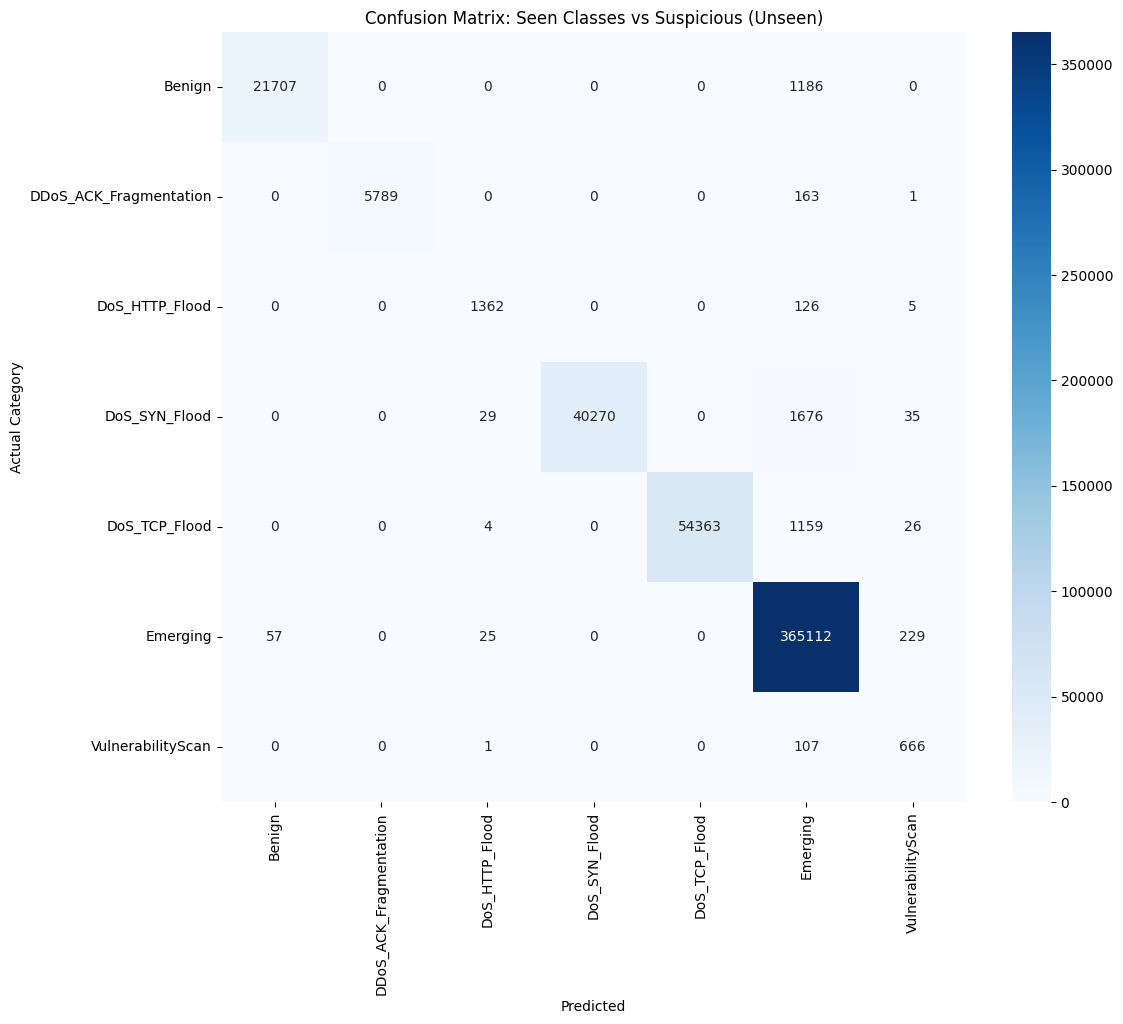


--- Detailed Analysis of Unseen Attack Detection ---


In [23]:

print("\nRunning Min–Max 3-way Inference on Mixed Test Set...")
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)
unique, counts = np.unique(y_pred, return_counts=True)
print(dict(zip(unique, counts)))

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)

report_dict=report_dict = classification_report(
    y_true_mapped,
    y_pred,
    output_dict=True,
    zero_division=0
)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})

## **Load dataset**

In [24]:
model = CNNTransformerBiLSTM(input_len=46, num_classes=num_classes).to(device)
model.load_state_dict(torch.load('gtrs_best_model.pth'))
model.eval()
print("Model loaded successfully!")

Model loaded successfully!



Running Min–Max 3-way Inference on Mixed Test Set...
{np.str_('Benign'): np.int64(19408), np.str_('DDoS_ACK_Fragmentation'): np.int64(772), np.str_('DoS_HTTP_Flood'): np.int64(1070), np.str_('DoS_SYN_Flood'): np.int64(242), np.str_('DoS_TCP_Flood'): np.int64(49546), np.str_('Emerging'): np.int64(422205), np.str_('VulnerabilityScan'): np.int64(855)}

Classification Report:
                        precision    recall  f1-score   support

                Benign       1.00      0.85      0.92     22893
DDoS_ACK_Fragmentation       1.00      0.13      0.23      5953
        DoS_HTTP_Flood       0.95      0.68      0.80      1493
         DoS_SYN_Flood       1.00      0.01      0.01     42010
         DoS_TCP_Flood       1.00      0.89      0.94     55552
              Emerging       0.86      1.00      0.93    365423
     VulnerabilityScan       0.70      0.77      0.73       774

              accuracy                           0.88    494098
             macro avg       0.93      0.62   

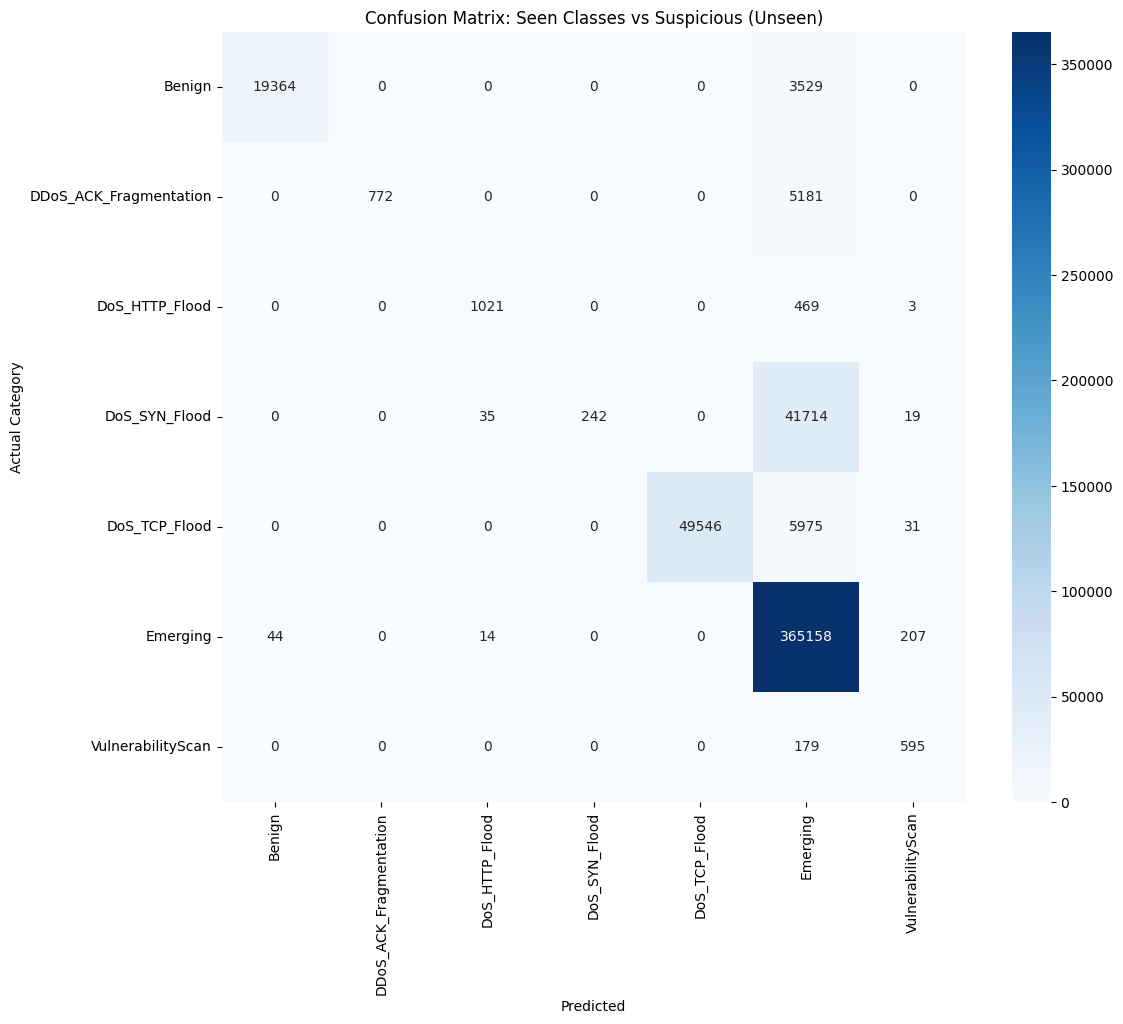


--- Detailed Analysis of Unseen Attack Detection ---


In [25]:

print("\nRunning Min–Max 3-way Inference on Mixed Test Set...")
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)
unique, counts = np.unique(y_pred, return_counts=True)
print(dict(zip(unique, counts)))

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)

report_dict=report_dict = classification_report(
    y_true_mapped,
    y_pred,
    output_dict=True,
    zero_division=0
)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})

In [26]:
# Split boundaries
n_seen = len(y_test_seen_str)
n_total = len(y_test_final_str)
assert len(y_pred) == n_total, "Pred length must match y_test_final_str length."

# Split into seen/unseen portions
y_true_seen = np.array(y_test_final_str[:n_seen], dtype=object)
y_pred_seen = np.array(y_pred[:n_seen], dtype=object)

y_true_unseen = np.array(y_test_final_str[n_seen:], dtype=object)   # keep real unseen names
y_pred_unseen = np.array(y_pred[n_seen:], dtype=object)

known_labels = list(le.classes_)
pred_cols = known_labels + ["Emerging"]


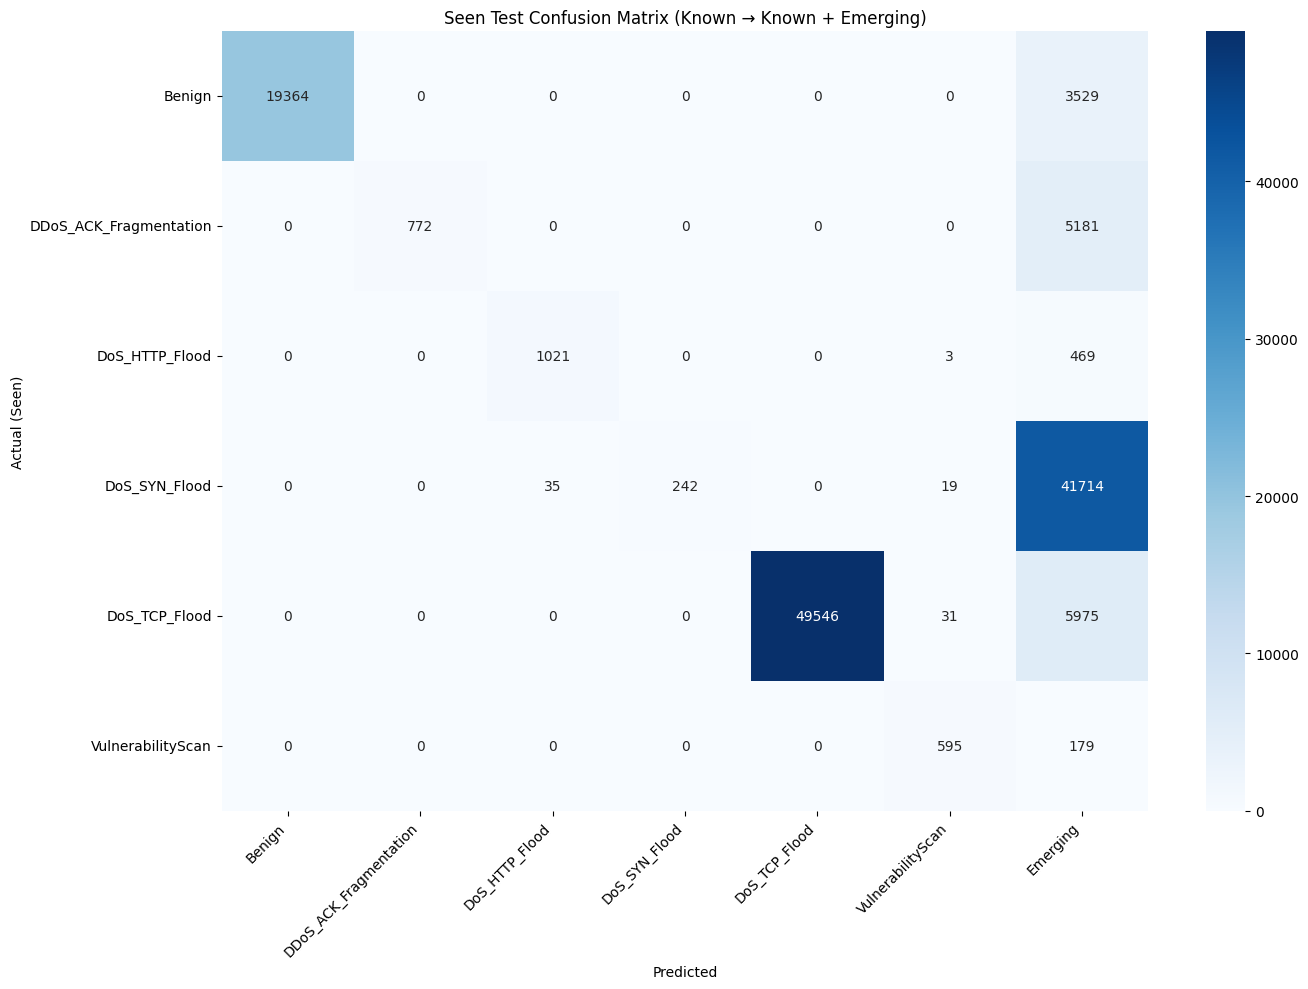

In [27]:
df_cm_seen = pd.crosstab(
    pd.Categorical(y_true_seen, categories=known_labels),
    pd.Categorical(y_pred_seen, categories=pred_cols),
    rownames=["Actual (Seen)"],
    colnames=["Predicted"],
    dropna=False
)

plt.figure(figsize=(14, 10))
sns.heatmap(df_cm_seen, annot=True, fmt="d", cmap="Blues")
plt.title("Seen Test Confusion Matrix (Known → Known + Emerging)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("cm_seen_known_plus_emerging.png", dpi=300)
plt.show()


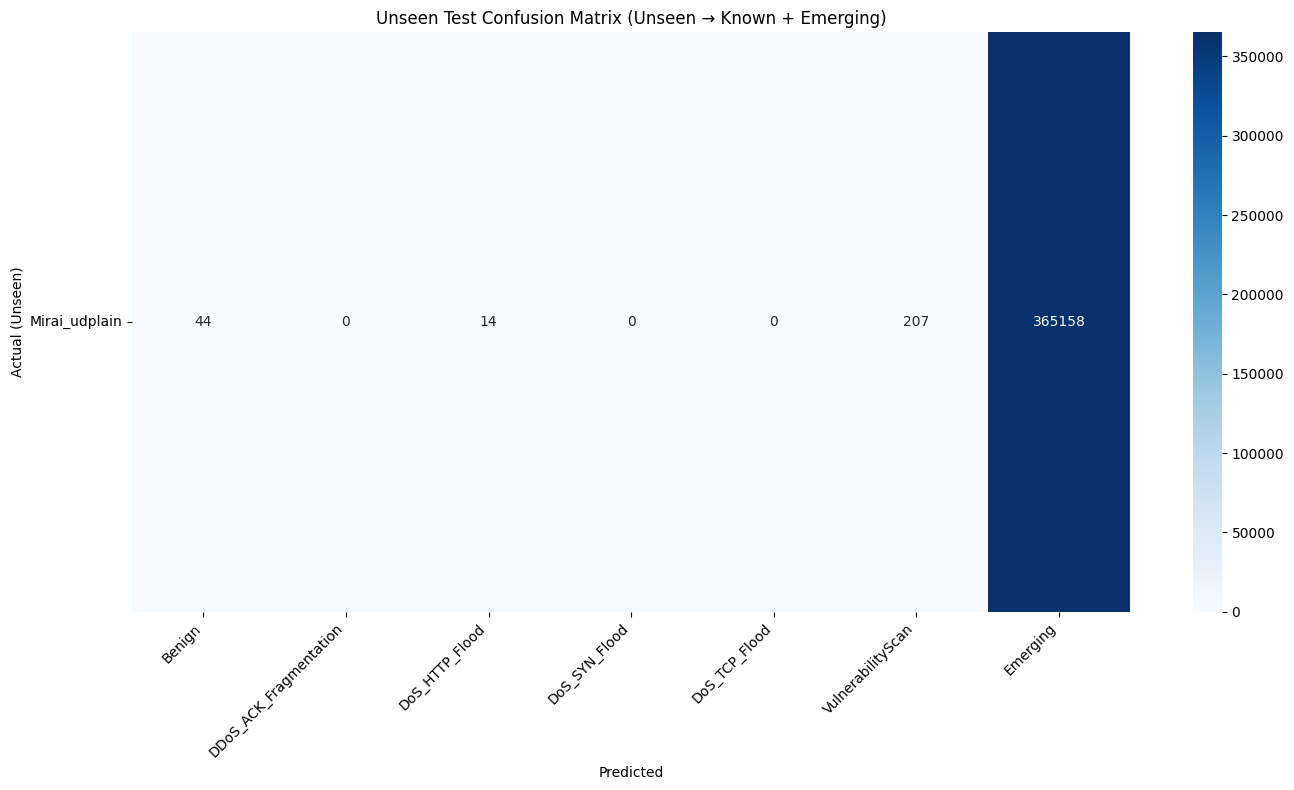

Unseen predicted as Emerging: 0.9992748130249054


In [28]:
unseen_labels = list(UNSEEN_CLASSES)

df_cm_unseen = pd.crosstab(
    pd.Categorical(y_true_unseen, categories=unseen_labels),
    pd.Categorical(y_pred_unseen, categories=pred_cols),
    rownames=["Actual (Unseen)"],
    colnames=["Predicted"],
    dropna=False
)

plt.figure(figsize=(14, 8))
sns.heatmap(df_cm_unseen, annot=True, fmt="d", cmap="Blues")
plt.title("Unseen Test Confusion Matrix (Unseen → Known + Emerging)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("cm_unseen_to_known_plus_emerging.png", dpi=300)
plt.show()

print("Unseen predicted as Emerging:", np.mean(y_pred_unseen == "Emerging"))


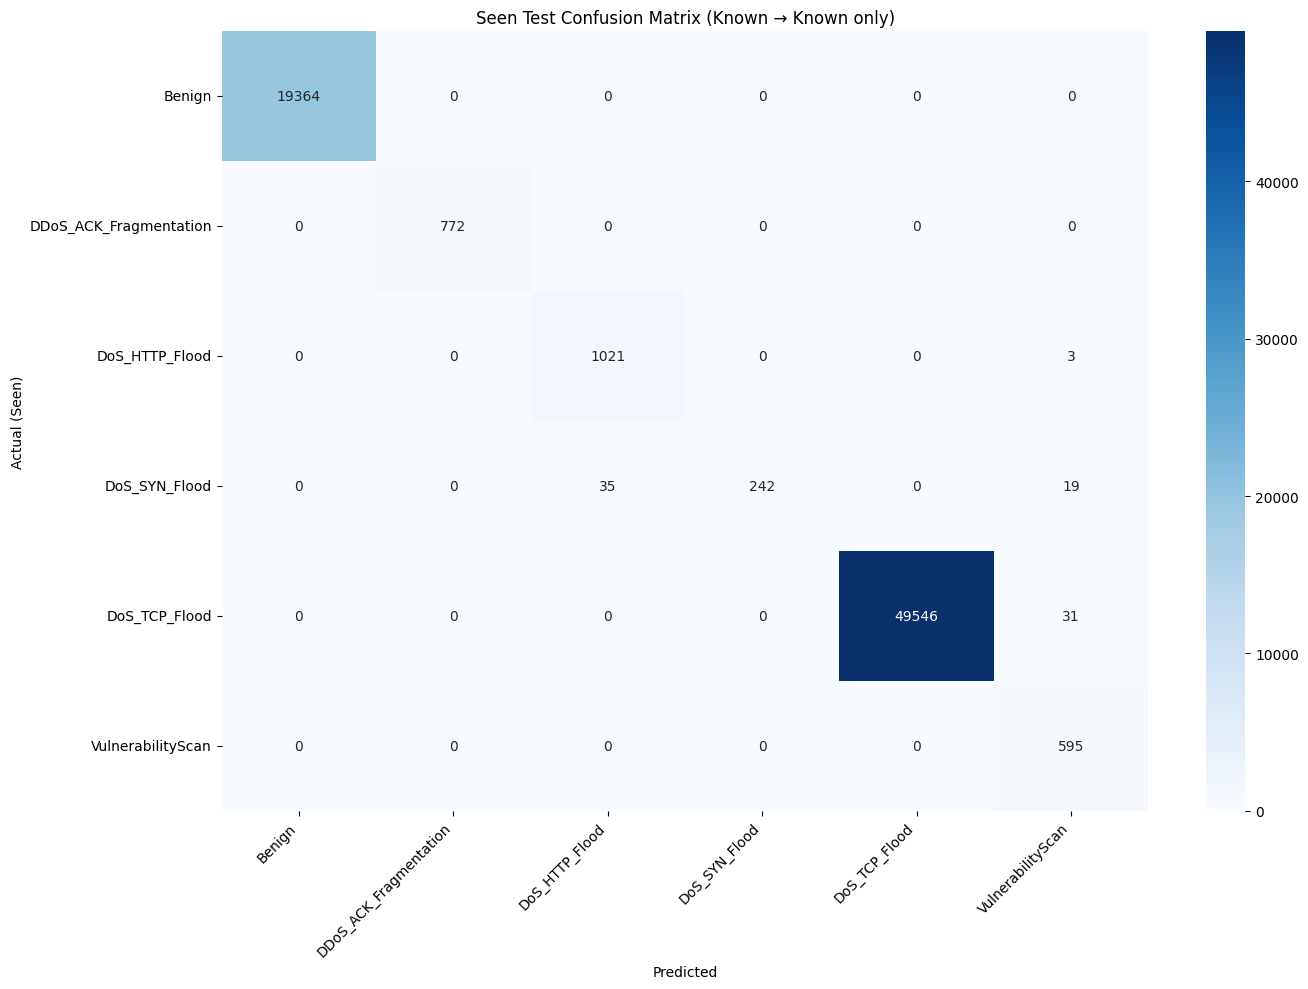

In [29]:
# Remove samples predicted as Emerging
mask_keep_seen = (y_pred_seen != "Emerging")

y_true_seen_eval = y_true_seen[mask_keep_seen]
y_pred_seen_eval = y_pred_seen[mask_keep_seen]

# Confusion matrix with known classes only
df_cm_seen = pd.crosstab(
    pd.Categorical(y_true_seen_eval, categories=known_labels),
    pd.Categorical(y_pred_seen_eval, categories=known_labels),
    rownames=["Actual (Seen)"],
    colnames=["Predicted"],
    dropna=False
)

plt.figure(figsize=(14, 10))
sns.heatmap(df_cm_seen, annot=True, fmt="d", cmap="Blues")
plt.title("Seen Test Confusion Matrix (Known → Known only)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("cm_seen_known_only.png", dpi=300)
plt.show()


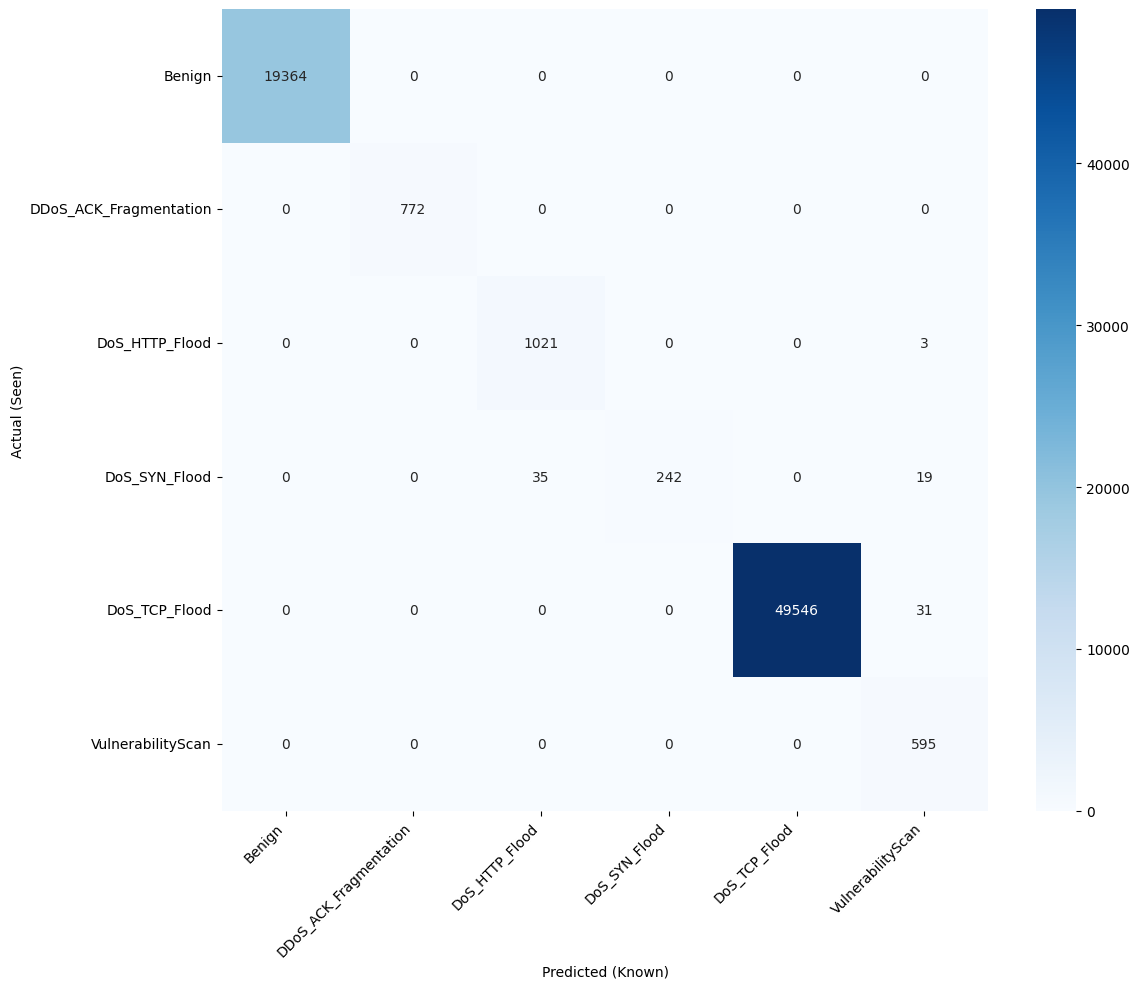

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

known_labels = list(le.classes_)
cmap_name = "Blues"

mask_keep_seen = (y_pred_seen != "Emerging")
y_true_seen_eval = y_true_seen[mask_keep_seen]
y_pred_seen_eval = y_pred_seen[mask_keep_seen]

df_cm_seen = pd.crosstab(
    pd.Categorical(y_true_seen_eval, categories=known_labels),
    pd.Categorical(y_pred_seen_eval, categories=known_labels),
    rownames=["Actual (Seen)"],
    colnames=["Predicted (Known)"],
    dropna=False
)

plt.figure(figsize=(12, 10))
sns.heatmap(df_cm_seen, annot=True, fmt="d", cmap=cmap_name)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("cm_seen_known_only.png", dpi=300)
plt.show()


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def plot_overall_metrics_bar(y_true, y_pred, title=None, save_path=None):
    """
    Creates a 4-bar chart: Accuracy, Precision, Recall, F1-score (in %)
    Uses weighted averaging for Precision/Recall/F1 (common for imbalanced data).
    """

    # Accuracy
    acc = accuracy_score(y_true, y_pred)

    # Precision/Recall/F1 (weighted)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    metrics = {
        "Accuracy": acc * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-score": f1 * 100,
    }

    labels = list(metrics.keys())
    values = list(metrics.values())

    # Colors similar to your sample (shades of blue)
    colors = ["#d9e6f2", "#a8c7da", "#5c97b6", "#2a6496"]

    plt.figure(figsize=(12, 7), dpi=150)
    bars = plt.bar(labels, values, color=colors, edgecolor="none")

    # Value labels on top (e.g., 98.87%)
    for b, v in zip(bars, values):
        plt.text(
            b.get_x() + b.get_width() / 2,
            v + 1.0,
            f"{v:.3f}%",
            ha="center",
            va="bottom",
            fontsize=14
        )

    plt.ylabel("Score (%)", fontsize=14)
    if title:
        plt.title(title, fontsize=16)

    plt.ylim(0, 110)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=12)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

    return metrics


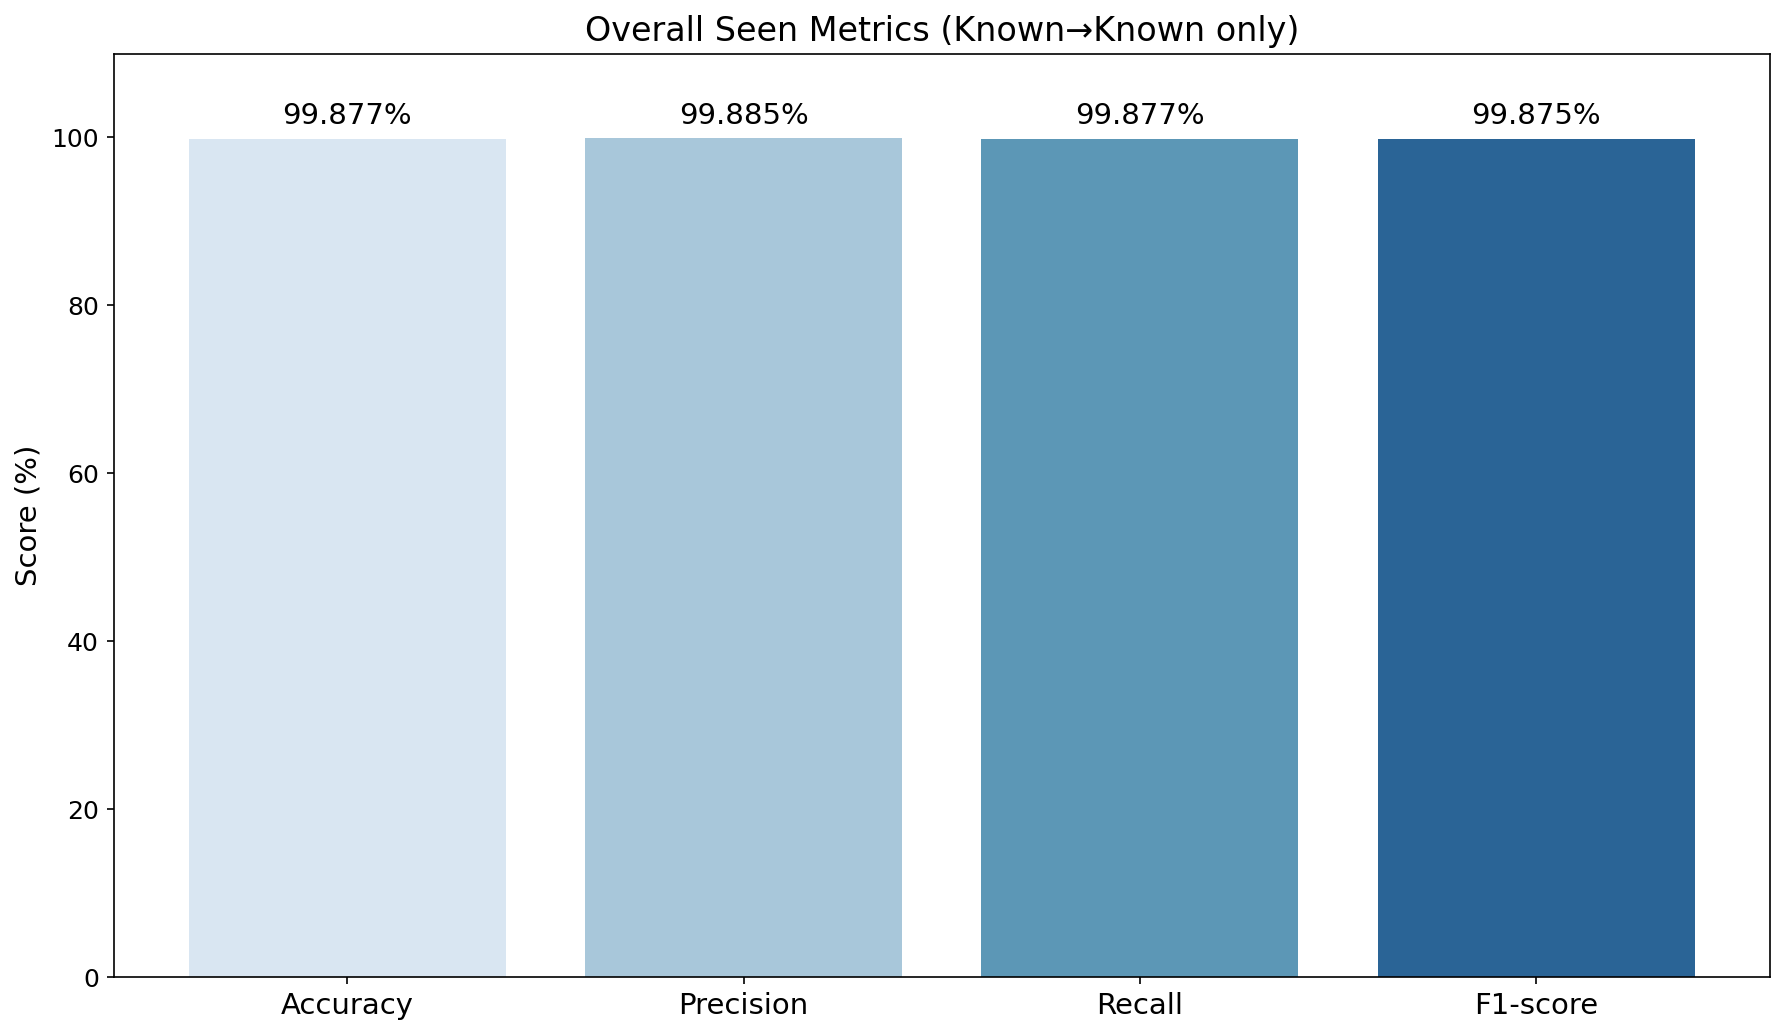

{'Accuracy': 99.87714301669737,
 'Precision': 99.88467566119928,
 'Recall': 99.87714301669737,
 'F1-score': 99.87533834617668}

In [32]:
# y_true_seen_eval, y_pred_seen_eval  (Emerging removed)
plot_overall_metrics_bar(
    y_true_seen_eval,
    y_pred_seen_eval,
    title="Overall Seen Metrics (Known→Known only)",
    save_path="overall_seen_metrics.png"
)



  PART B: UNSEEN (UNKNOWN) ATTACKS

Total Unseen Samples: 365423
Detected as Emerging: 365158
Overall Detection Rate: 99.93%


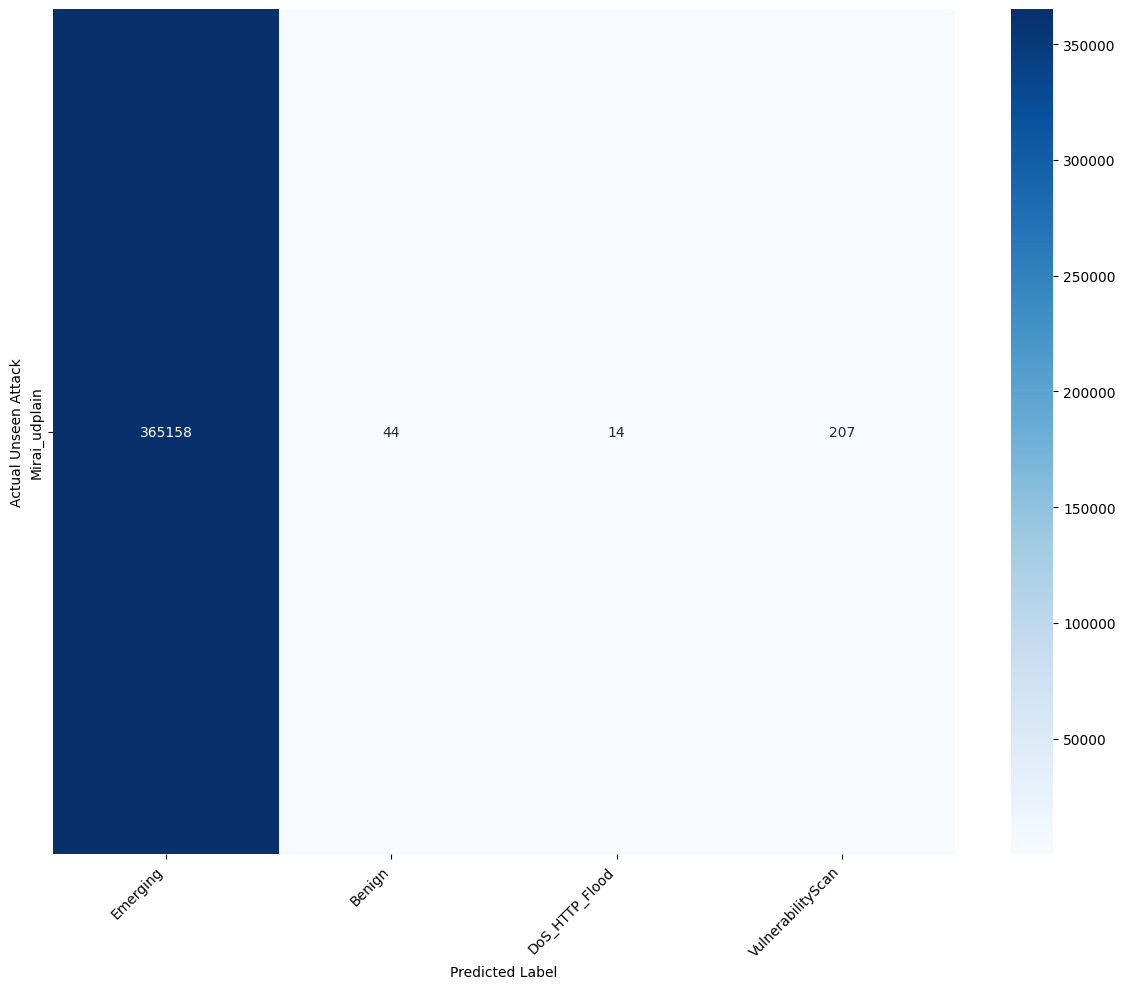

/tmp/ipykernel_55/38691516.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=breakdown, x='Attack_Type', y='Detection_Rate', palette='magma')


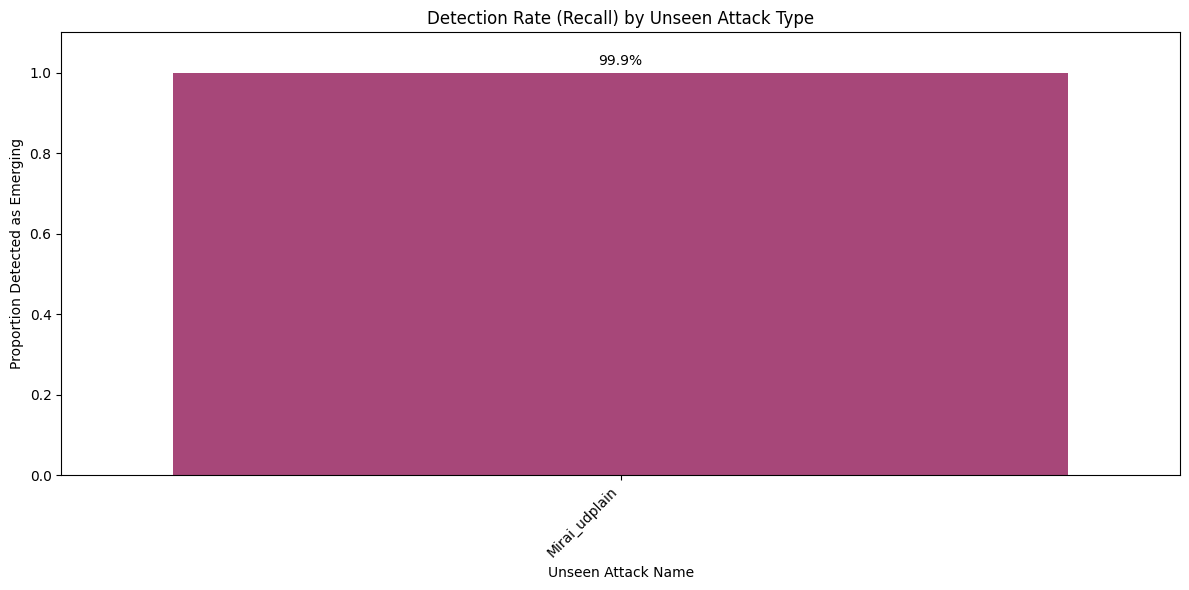


Detailed Detection Rates:
     Attack_Type  Detection_Rate
0  Mirai_udplain        0.999275


In [33]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.metrics import classification_report
# import pandas as pd
# import numpy as np
# import torch

# # --- 1. Inference Function (Kept as is) ---
# def predict_gtrs(model, loader, thresholds, le, temperature=1.0):
#     model.eval()
#     preds = []
    
#     with torch.no_grad():
#         for inputs, _ in loader: 
#             inputs = inputs.to(device)
#             outputs = model(inputs)
            
#             # Temperature Scaling
#             probs_batch = torch.softmax(outputs / temperature, dim=1).cpu().numpy()
            
#             for i in range(len(probs_batch)):
#                 p_vec = probs_batch[i]
#                 pred_idx = np.argmax(p_vec)
#                 conf = p_vec[pred_idx]
                
#                 t = thresholds[pred_idx]
                
#                 if conf >= t['alpha']:
#                     preds.append(le.inverse_transform([pred_idx])[0])
#                 else:
#                     preds.append('Emerging')
                    
#     return np.array(preds)

# # --- 2. Run Inference ---
# print("\nRunning Inference on Mixed Test Set...")
# # Ensure 'device' is set (e.g., device = torch.device('cuda'))
# y_pred = predict_gtrs(model, test_loader, opt_thresholds, le, temperature=1.0)

# # --- 3. Separate Data (Seen vs Unseen) ---
# known_classes = set(le.classes_)

# # Create boolean mask
# is_seen_mask = np.array([label in known_classes for label in y_test_final_str])

# # Split
# y_true_seen = np.array(y_test_final_str)[is_seen_mask]
# y_pred_seen = y_pred[is_seen_mask]

# y_true_unseen = np.array(y_test_final_str)[~is_seen_mask]
# y_pred_unseen = y_pred[~is_seen_mask]

# # ==========================================
# # PART A: SEEN ATTACKS ANALYSIS
# # ==========================================
# print("\n" + "="*40)
# print("  PART A: SEEN (KNOWN) ATTACKS")
# print("="*40)

# if len(y_true_seen) > 0:
#     # 1. Classification Report
#     print("\n--- Classification Report (Seen) ---")
#     report_dict = classification_report(y_true_seen, y_pred_seen, output_dict=True, zero_division=0)
#     print(classification_report(y_true_seen, y_pred_seen, zero_division=0))

#     # 2. Confusion Matrix (Using Crosstab for safety)
#     df_cm_seen = pd.crosstab(
#         pd.Series(y_true_seen, name='Actual'),
#         pd.Series(y_pred_seen, name='Predicted')
#     )
#     # Remove 'Emerging' column if you want to hide False Positives (Optional)
#     # if 'Emerging' in df_cm_seen.columns: df_cm_seen = df_cm_seen.drop(columns=['Emerging'])

#     plt.figure(figsize=(12, 10))
#     sns.heatmap(df_cm_seen, annot=True, fmt='d', cmap='Blues')
#     plt.title("Confusion Matrix: Seen Attacks")
#     plt.xticks(rotation=45, ha='right')
#     plt.tight_layout()
#     plt.savefig("seen_attacks.png")
#     plt.show()

#     # 3. Bar Chart: F1-Score per Class
#     # Extract F1 scores, ignoring 'accuracy', 'macro avg', etc.
#     classes = [k for k in report_dict.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]
#     f1_scores = [report_dict[k]['f1-score'] for k in classes]

#     plt.figure(figsize=(12, 6))
#     sns.barplot(x=classes, y=f1_scores, palette='viridis')
#     plt.title("F1-Score per Known Class")
#     plt.ylabel("F1 Score")
#     plt.xticks(rotation=45, ha='right')
#     plt.ylim(0, 1.1)
#     plt.tight_layout()
#     plt.savefig("seen_f1.png")
#     plt.show()

# else:
#     print("No Seen samples found.")

# ==========================================
# PART B: UNSEEN ATTACKS ANALYSIS
# ==========================================
print("\n" + "="*40)
print("  PART B: UNSEEN (UNKNOWN) ATTACKS")
print("="*40)

if len(y_true_unseen) > 0:
    # 1. Detection Rates
    correctly_detected = np.sum(y_pred_unseen == 'Emerging')
    total_unseen = len(y_true_unseen)
    overall_rate = correctly_detected / total_unseen
    
    print(f"\nTotal Unseen Samples: {total_unseen}")
    print(f"Detected as Emerging: {correctly_detected}")
    print(f"Overall Detection Rate: {overall_rate:.2%}")

    # 2. Confusion Matrix (Unseen Actuals vs. Predictions)
    df_cm_unseen = pd.crosstab(
        pd.Series(y_true_unseen, name='Actual Unseen Attack'),
        pd.Series(y_pred_unseen, name='Predicted Label')
    )
    
    # Move 'Emerging' to first column
    cols = list(df_cm_unseen.columns)
    if 'Emerging' in cols:
        cols.remove('Emerging')
        cols.insert(0, 'Emerging')
        df_cm_unseen = df_cm_unseen[cols]

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_unseen, annot=True, fmt='d', cmap='Blues')
    # plt.title(f"Confusion Matrix: Unseen Detection (Overall Rate: {overall_rate:.1%})")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("unseen_detection.png")
    plt.show()

    # 3. Bar Chart: Detection Rate per Attack Type
    # Calculate % detected as Emerging for each specific unseen label
    analysis_df = pd.DataFrame({'Actual': y_true_unseen, 'Predicted': y_pred_unseen})
    breakdown = analysis_df.groupby('Actual')['Predicted'].apply(lambda x: (x == 'Emerging').mean()).reset_index()
    breakdown.columns = ['Attack_Type', 'Detection_Rate']
    breakdown = breakdown.sort_values('Detection_Rate', ascending=False)

    plt.figure(figsize=(12, 6))
    sns.barplot(data=breakdown, x='Attack_Type', y='Detection_Rate', palette='magma')
    plt.title("Detection Rate (Recall) by Unseen Attack Type")
    plt.ylabel("Proportion Detected as Emerging")
    plt.xlabel("Unseen Attack Name")
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 1.1)
    
    # Add text labels on bars
    for index, row in breakdown.iterrows():
        plt.text(index, row.Detection_Rate + 0.02, f"{row.Detection_Rate:.1%}", color='black', ha="center")

    plt.tight_layout()
    plt.savefig("unseen_detection_rate.png")
    plt.show()

    print("\nDetailed Detection Rates:")
    print(breakdown)

else:
    print("No Unseen samples found.")



/tmp/ipykernel_55/3378034611.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax_overall = sns.barplot(


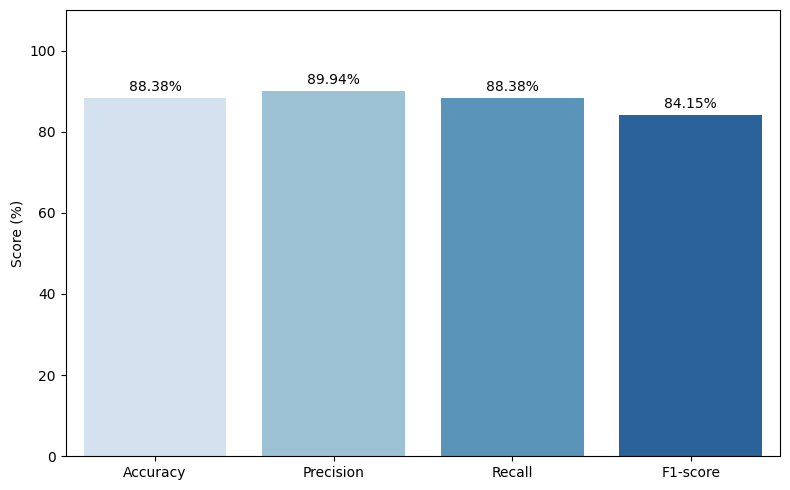

In [34]:
# ==========================================
# 4) Overall Metrics Visualization (Accuracy, Precision, Recall, F1)
# ==========================================

# Get overall metrics (use weighted avg for multi-class)
acc = report_dict["accuracy"] * 100
prec = report_dict["weighted avg"]["precision"] * 100
rec = report_dict["weighted avg"]["recall"] * 100
f1 = report_dict["weighted avg"]["f1-score"] * 100

overall_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [acc, prec, rec, f1]
})

plt.figure(figsize=(8, 5))
ax_overall = sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score (%)",
    palette=sns.color_palette(cmap_name, n_colors=len(overall_df))
)

plt.title("")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 110)

# Add values on top of bars
for container in ax_overall.containers:
    ax_overall.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_seen_metrics.png", dpi=300)
plt.show()


In [35]:
print("\n--- Generating ROC Curves ---")
# Filter test set to only include SEEN classes for valid ROC calculation
mask_seen = np.isin(y_test_final_str, SEEN_CLASSES)
y_test_seen_only = y_test_final_str[mask_seen]
X_test_seen_only = X_test_final[mask_seen] 

# Create a temporary loader
seen_ds = IoTDataset(X_test_seen_only, np.zeros(len(X_test_seen_only))) 
seen_loader = DataLoader(seen_ds, batch_size=CONFIG['batch_size'], shuffle=False)

# Get raw probabilities
probs_seen, _ = get_probabilities(model, seen_loader) 

# Binarize labels
classes = list(le.classes_)
y_test_bin = label_binarize(y_test_seen_only, classes=classes)
n_classes = y_test_bin.shape[1]

# Plot
plt.figure(figsize=(10, 8))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), probs_seen.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-average (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot each class
colors = cycle(sns.color_palette("husl", n_classes)) # Distinct colors for lines
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs_seen[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curve', fontsize=16)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/multiclass_roc_curve.png', dpi=300)
plt.show()

print("\nAll charts generated and saved.")


--- Generating ROC Curves ---


NameError: name 'get_probabilities' is not defined

## **Lime**

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_best_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 6 
}

SEEN_CLASSES = [
    'Benign', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 
    'DDoS', 'Mirai', 'VulnerabilityScan'
]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare SHAP Data & Explainer ---
print("Initializing SHAP KernelExplainer...")
n_features = CONFIG['input_shape'][0]
feature_names = [f"Feature_{i}" for i in range(n_features)] 

# Create background data (K-means summary is faster for KernelExplainer)
# We need a small background dataset to keep it fast
# Replace torch.randn with actual X_train samples in real usage for meaningful results
background_data_np = np.random.rand(50, n_features).astype(np.float32)

# Define prediction function for KernelExplainer
def predict_proba_shap(data_numpy):
    # data_numpy: (N, features)
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# Using KernelExplainer (Model Agnostic) to avoid PyTorch Gradient issues
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)

# --- 5. Compute SHAP Values ---
print("Computing SHAP values (this may take a moment)...")
test_data_np = np.random.rand(10, n_features).astype(np.float32) # Explain 10 samples
shap_values = explainer.shap_values(test_data_np, nsamples=100) # nsamples controls speed/accuracy

# shap_values is a list of arrays (one for each class).
# For summary plot, we can use the list directly or pick a class.
# For decision/waterfall, we need values for a specific class and instance.

# --- 6. Visualizations (Matching Paper Style) ---

# A. Summary Plot (Global Interpretability)
print("Generating Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=feature_names, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot.png')
plt.close()
print("Saved 'shap_summary_plot.png'")

# B. Decision Plot
# Explain Sample 0 for its predicted class
pred_probs = predict_proba_shap(test_data_np[0:1])[0]
pred_class_idx = np.argmax(pred_probs)
print(f"Generating Decision Plot for Sample 0 (Predicted: {SEEN_CLASSES[pred_class_idx]})...")

plt.figure()
# KernelExplainer.expected_value is a list (one per class)
base_value = explainer.expected_value[pred_class_idx]
shap_vals_sample = shap_values[pred_class_idx][0]

shap.decision_plot(
    base_value,
    shap_vals_sample,
    test_data_np[0],
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Decision Plot: Sample 0 ({SEEN_CLASSES[pred_class_idx]})")
plt.tight_layout()
plt.savefig('shap_decision_plot.png')
plt.close()
print("Saved 'shap_decision_plot.png'")

# C. Waterfall Plot
print("Generating Waterfall Plot...")
plt.figure()
try:
    # Create Explanation object for modern SHAP plots
    exp = shap.Explanation(
        values=shap_vals_sample,
        base_values=base_value,
        data=test_data_np[0],
        feature_names=feature_names
    )
    shap.waterfall_plot(exp, show=False)
    plt.title(f"SHAP Waterfall Plot: Sample 0")
    plt.tight_layout()
    plt.savefig('shap_waterfall_plot.png')
    plt.close()
    print("Saved 'shap_waterfall_plot.png'")
except Exception as e:
    print(f"Waterfall plot skipped: {e}")

print("\nSHAP analysis complete.")

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 6 
}

SEEN_CLASSES = [
    'Benign', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 
    'DDoS', 'Mirai', 'VulnerabilityScan'
]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare SHAP Data (KernelExplainer Setup) ---
print("Initializing SHAP KernelExplainer...")
n_features = CONFIG['input_shape'][0]
feature_names = [f"Feature_{i}" for i in range(n_features)] 

# Create background data for KernelExplainer
# KernelExplainer is slow, so we summarize the background using k-means or just take a small sample
# Replace random data with X_train sample in real usage
background_data_np = np.random.rand(50, n_features).astype(np.float32)

# Define prediction function for KernelExplainer
# It takes a numpy array of shape (N, features) and returns probabilities (N, classes)
def predict_proba_shap(data_numpy):
    # Reshape if necessary (N, features) -> (N, features, 1) for our model input
    # Our model expects (Batch, Features, 1) effectively before the permute
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
        
    return probs.cpu().numpy()

# Initialize KernelExplainer with the prediction function and background data
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)

# --- 5. Compute SHAP Values ---
print("Computing SHAP values (this may take a moment)...")
# Calculate SHAP values for a set of test samples
# We'll use a small batch of test data to keep runtime reasonable
test_data_np = np.random.rand(10, n_features).astype(np.float32) 

# Run KernelExplainer
# nsamples controls the number of evaluations (higher = more accurate but slower)
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# --- 6. Visualizations (Per-Class Analysis) ---

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
# shap_values is a list of arrays [class 0, class 1, ...], summary_plot handles this list for multiclass
shap.summary_plot(shap_values, test_data_np, feature_names=feature_names, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class Explanations (Decision & Waterfall)
print("\nGenerating Per-Class Explanation Plots...")

# Get predictions to find representative samples
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0]
    print(f"--> Generating plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # 1. Decision Plot
    plt.figure()
    # KernelExplainer.expected_value is a list/array of base values
    base_val = explainer.expected_value[class_idx]
    
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=feature_names,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # 2. Waterfall Plot
    plt.figure()
    try:
        # Create Explanation object for waterfall plot
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=feature_names
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nSHAP analysis complete. Check generated files for each class.")

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 6 
}

SEEN_CLASSES = [
    'Benign', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 
    'DDoS', 'Mirai', 'VulnerabilityScan'
]

# Explicit Feature Names from CICIoT2023 Dataset
FEATURE_NAMES = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate',
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number',
    'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count',
    'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP',
    'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT',
    'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight'
]

# Validate feature count matches config
if len(FEATURE_NAMES) != CONFIG['input_shape'][0]:
    print(f"Warning: Feature name list length ({len(FEATURE_NAMES)}) does not match input shape ({CONFIG['input_shape'][0]}). Truncating or padding.")
    # Adjust logic if needed, but for now we assume they match or we stick to generic names if mismatch
    if len(FEATURE_NAMES) > CONFIG['input_shape'][0]:
        FEATURE_NAMES = FEATURE_NAMES[:CONFIG['input_shape'][0]]
    else:
        FEATURE_NAMES += [f"Feature_{i}" for i in range(len(FEATURE_NAMES), CONFIG['input_shape'][0])]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare SHAP Data (KernelExplainer Setup) ---
print("Initializing SHAP KernelExplainer...")

# Create background data for KernelExplainer
# We generate a synthetic background (replace with X_train sample in real usage)
background_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32)

# Define prediction function for KernelExplainer
def predict_proba_shap(data_numpy):
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# Initialize KernelExplainer
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)

# --- 5. Compute SHAP Values ---
print("Computing SHAP values (this may take a moment)...")
# Calculate SHAP values for a set of test samples
test_data_np = np.random.rand(10, CONFIG['input_shape'][0]).astype(np.float32) 

# Run KernelExplainer
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# --- 6. Visualizations (Per-Class Analysis) ---

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=FEATURE_NAMES, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class Explanations (Decision & Waterfall)
print("\nGenerating Per-Class Explanation Plots...")

# Get predictions to find representative samples
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0]
    print(f"--> Generating plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # 1. Decision Plot
    plt.figure()
    base_val = explainer.expected_value[class_idx]
    
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=FEATURE_NAMES,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # 2. Waterfall Plot
    plt.figure()
    try:
        # Create Explanation object for waterfall plot
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=FEATURE_NAMES
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nSHAP analysis complete. Check generated files for each class.")

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 6 
}

SEEN_CLASSES = [
    'Benign', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 
    'DDoS', 'Mirai', 'VulnerabilityScan'
]

# Explicit Feature Names from CICIoT2023 Dataset
FEATURE_NAMES = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate',
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number',
    'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count',
    'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP',
    'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT',
    'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight'
]

# Validate feature count matches config
if len(FEATURE_NAMES) != CONFIG['input_shape'][0]:
    print(f"Warning: Feature name list length ({len(FEATURE_NAMES)}) does not match input shape ({CONFIG['input_shape'][0]}). Truncating or padding.")
    if len(FEATURE_NAMES) > CONFIG['input_shape'][0]:
        FEATURE_NAMES = FEATURE_NAMES[:CONFIG['input_shape'][0]]
    else:
        FEATURE_NAMES += [f"Feature_{i}" for i in range(len(FEATURE_NAMES), CONFIG['input_shape'][0])]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare SHAP Data (KernelExplainer Setup) ---
print("Initializing SHAP KernelExplainer...")

# Create background data for KernelExplainer
# We generate a synthetic background (replace with X_train sample in real usage)
background_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32)

# Define prediction function for KernelExplainer
def predict_proba_shap(data_numpy):
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# Initialize KernelExplainer
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)

# --- 5. Compute SHAP Values ---
print("Computing SHAP values for test samples...")
# Generate dummy test data for demonstration (Replace with X_test in real usage)
# We create 50 random samples to ensure we likely hit different classes
test_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32) 

# Run KernelExplainer
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# --- 6. Visualizations (Per-Class Analysis) ---

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=FEATURE_NAMES, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class Explanations (Decision & Waterfall)
print("\nGenerating Per-Class Explanation Plots...")

# Get predictions to find representative samples for each class
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0] # Pick the first sample found for this class
    print(f"--> Generating plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # 1. Decision Plot
    # Shows the "path" of feature contributions from base value to final prediction
    plt.figure()
    base_val = explainer.expected_value[class_idx]
    
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=FEATURE_NAMES,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # 2. Waterfall Plot
    # Shows detailed positive/negative contributions for top features
    plt.figure()
    try:
        # Create Explanation object required for waterfall plot
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=FEATURE_NAMES
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nSHAP analysis complete. Check generated files for each class.")

**New COde**

In [36]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

# SHAP + LIME
import shap
from lime.lime_tabular import LimeTabularExplainer

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

def to_2d(X):
    """Convert (N,F,1) -> (N,F) or keep (N,F)."""
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

def model_predict_proba_numpy(X_2d, model, device, batch_size=512):
    """
    Returns probabilities (N, C) for SHAP/LIME.
    Expects X_2d shape: (N, F)
    Your model expects (N,F,1), so we reshape.
    """
    model.eval()
    X_2d = np.asarray(X_2d, dtype=np.float32)
    probs_all = []

    with torch.no_grad():
        for i in range(0, len(X_2d), batch_size):
            xb = X_2d[i:i+batch_size]
            xb_t = torch.tensor(xb, dtype=torch.float32, device=device).unsqueeze(-1)  # (N,F,1)
            logits = model(xb_t)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs_all.append(probs)

    return np.vstack(probs_all)


In [37]:
X_train_2d = to_2d(X_train)
X_test_2d  = to_2d(X_test_final)

# ---- Choose a small SHAP background set (fast + stable) ----
# 100-300 rows is usually enough for KernelExplainer
bg_size = min(200, len(X_train_2d))
background = shap.sample(X_train_2d, bg_size, random_state=42)

# ---- Choose explain samples (for waterfall + LIME) ----
explain_size = min(10, len(X_test_2d))
X_explain = X_test_2d[:explain_size]


In [38]:
# SHAP KernelExplainer using probability outputs
f_shap = lambda x: model_predict_proba_numpy(x, model, device, batch_size=512)

explainer = shap.KernelExplainer(f_shap, background)

# Compute SHAP values for a subset (for speed)
shap_eval_size = min(500, len(X_test_2d))
X_shap_eval = X_test_2d[:shap_eval_size]

# nsamples controls runtime; increase if you need more accurate SHAP
shap_values = explainer.shap_values(X_shap_eval, nsamples=200)
# shap_values is usually a list: [ (N,F) for class0, (N,F) for class1, ... ]


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/500 [00:00<?, ?it/s]

In [39]:
print("X_shap_eval shape:", X_shap_eval.shape)
if isinstance(shap_values, list):
    print("shap_values is a list. length:", len(shap_values))
    for i, sv in enumerate(shap_values[:min(3, len(shap_values))]):
        print(f"  class {i} shap shape:", np.array(sv).shape)
else:
    print("shap_values is an array. shape:", np.array(shap_values).shape)


X_shap_eval shape: (500, 46)
shap_values is an array. shape: (500, 46, 6)


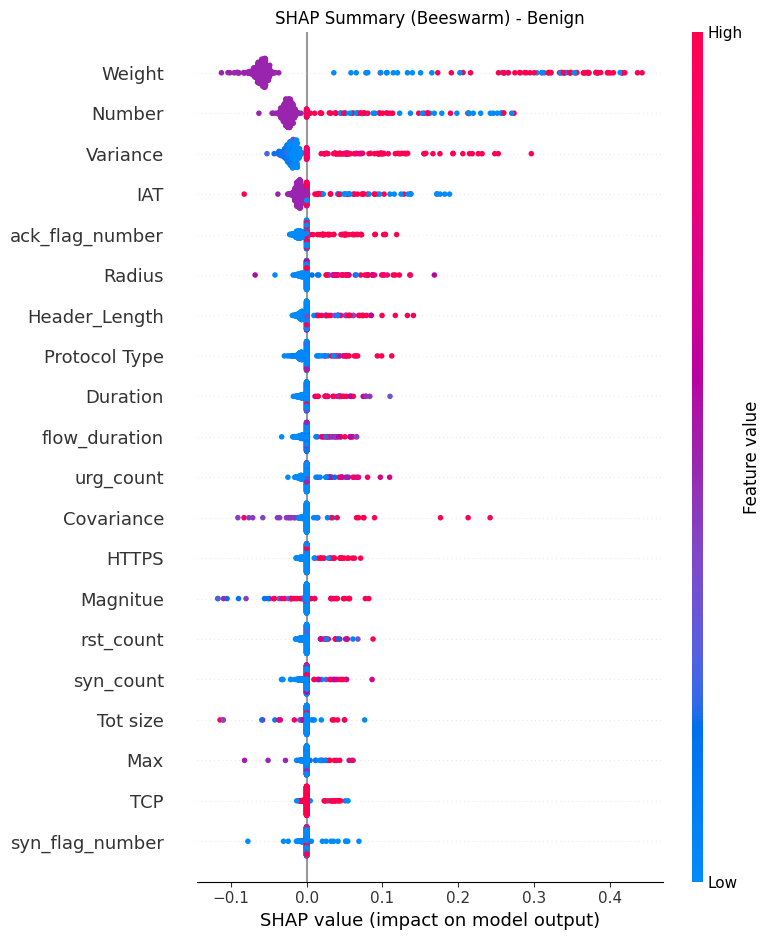

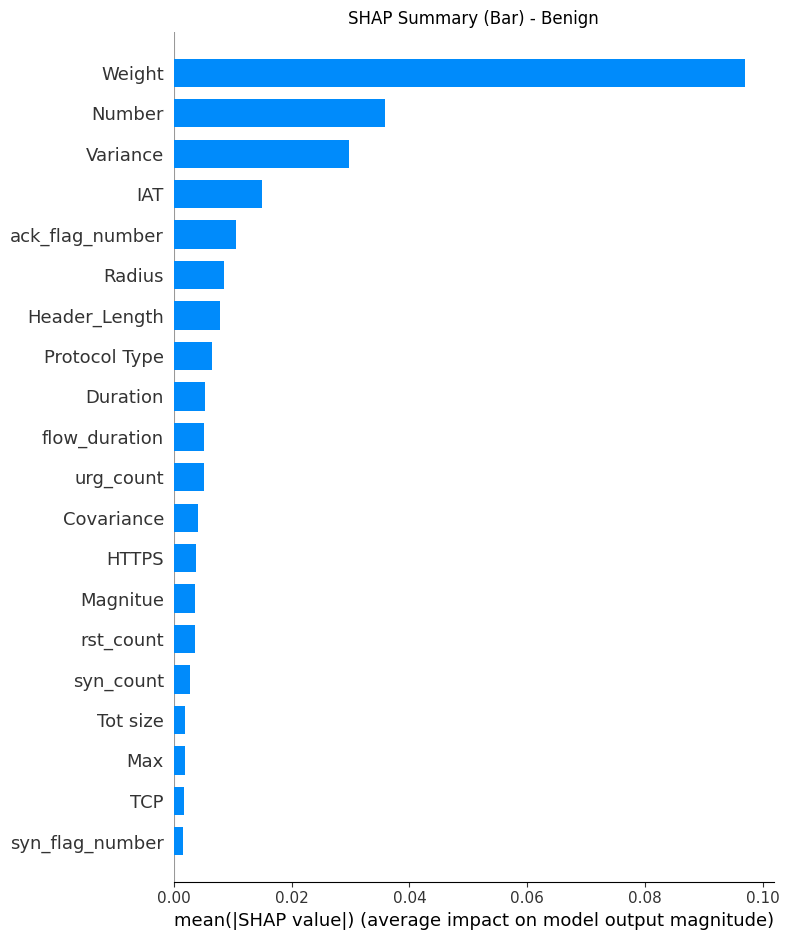

In [40]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

class_idx = 0
class_name = le.classes_[class_idx] if class_idx < len(le.classes_) else f"class_{class_idx}"

# Slice class SHAP: (N,F,C) -> (N,F)
sv_class = shap_values[:, :, class_idx]
assert sv_class.shape == X_shap_eval.shape, f"{sv_class.shape} vs {X_shap_eval.shape}"

# --- Beeswarm ---
plt.figure()
shap.summary_plot(sv_class, X_shap_eval, feature_names=feature_names, show=False)
plt.title(f"SHAP Summary (Beeswarm) - {class_name}")
plt.tight_layout()
plt.savefig(os.path.join(save_dir, f"shap_summary_beeswarm_{class_name}.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Bar (global importance) ---
plt.figure()
shap.summary_plot(sv_class, X_shap_eval, feature_names=feature_names, plot_type="bar", show=False)
plt.title(f"SHAP Summary (Bar) - {class_name}")
plt.tight_layout()
plt.savefig(os.path.join(save_dir, f"shap_summary_bar_{class_name}.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

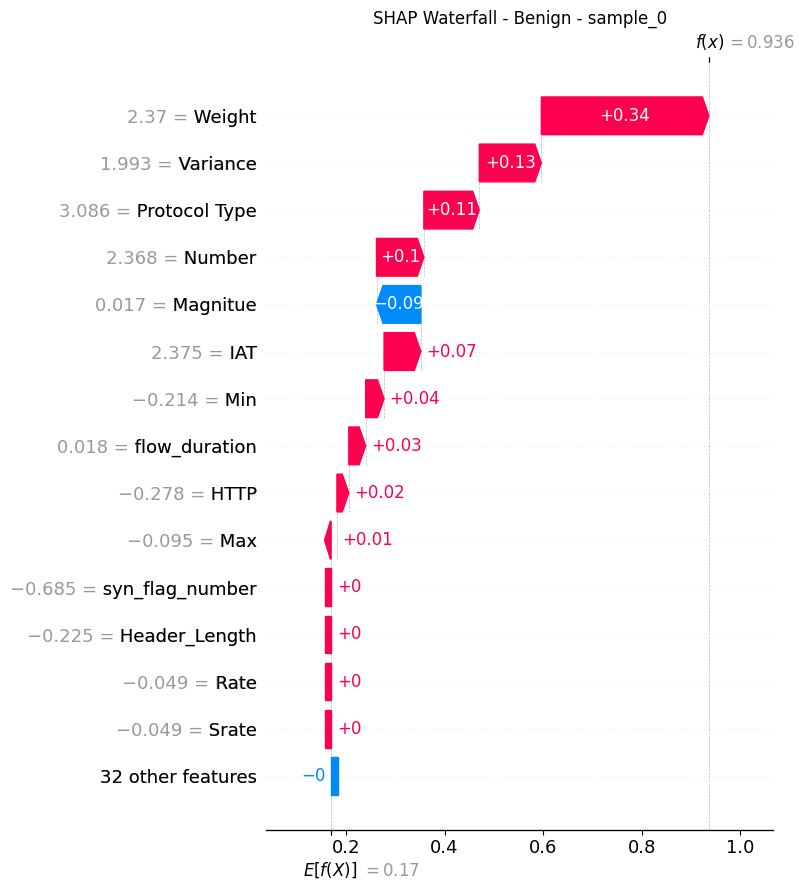

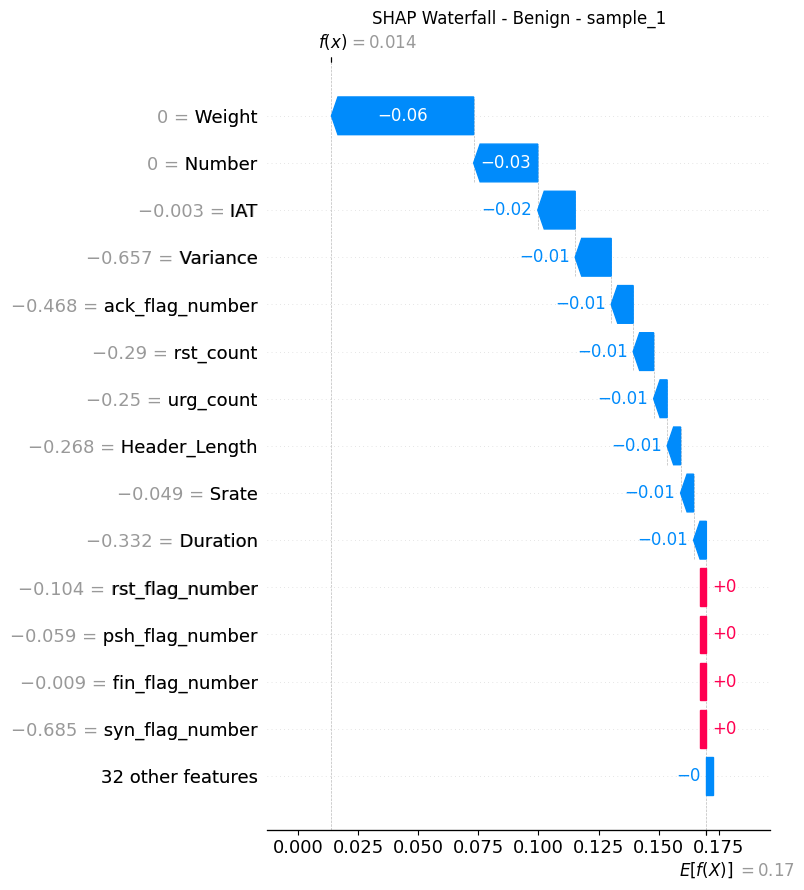

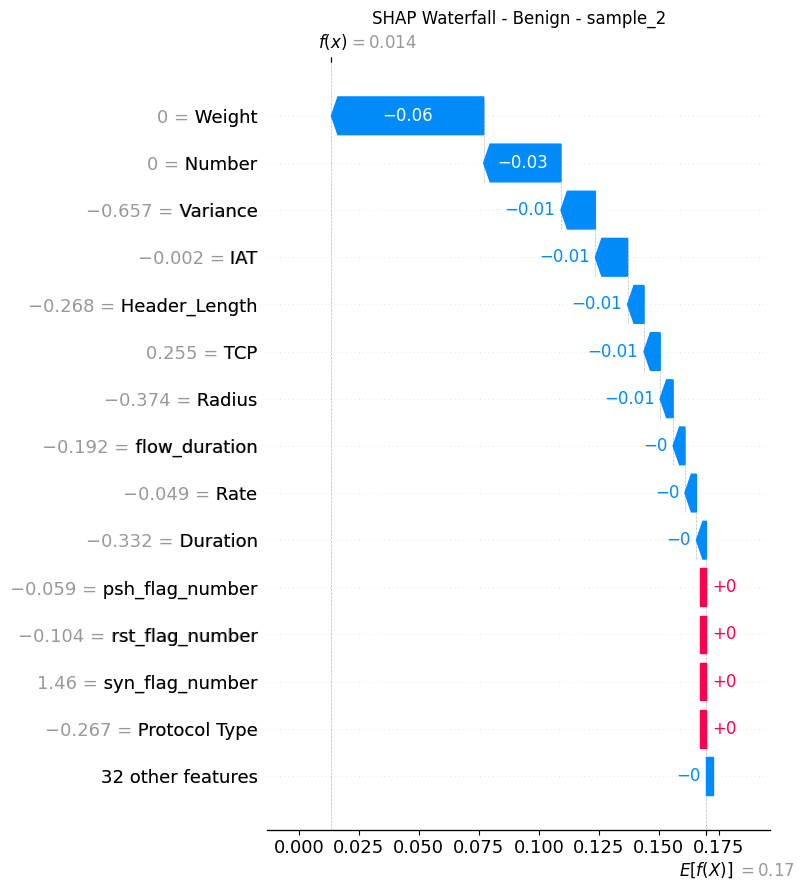

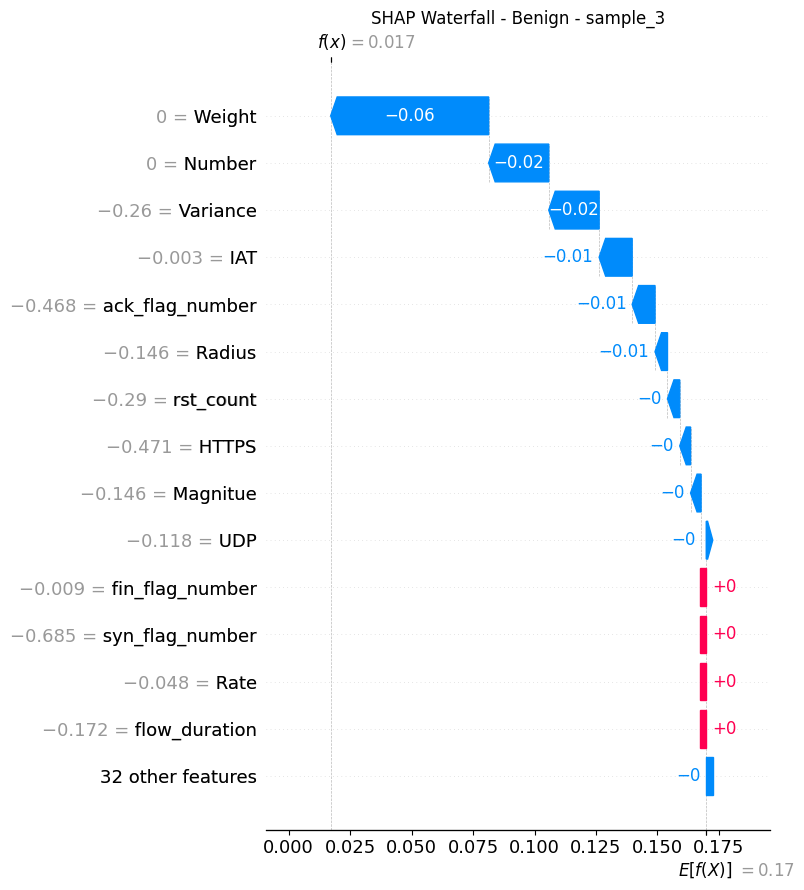

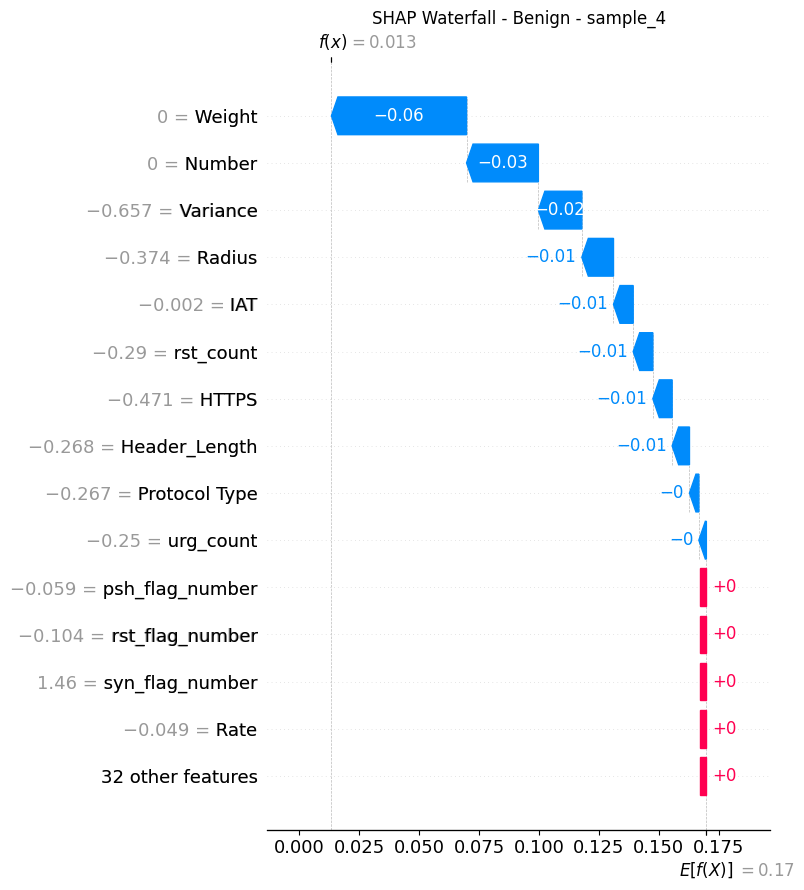

In [41]:
# ---- Base value for the selected class ----
# KernelExplainer expected_value can be scalar, (C,), or list
ev = explainer.expected_value
if isinstance(ev, (list, tuple, np.ndarray)) and len(np.atleast_1d(ev)) > 1:
    base_value = np.atleast_1d(ev)[class_idx]
else:
    base_value = float(np.atleast_1d(ev)[0])

# Choose a few samples for waterfall
waterfall_k = min(5, X_shap_eval.shape[0])

for i in range(waterfall_k):
    exp = shap.Explanation(
        values=sv_class[i],          # (F,)
        base_values=base_value,
        data=X_shap_eval[i],         # (F,)
        feature_names=feature_names
    )

    plt.figure()
    shap.plots.waterfall(exp, max_display=15, show=False)
    plt.title(f"SHAP Waterfall - {class_name} - sample_{i}")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"shap_waterfall_{class_name}_sample_{i}.png"),
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


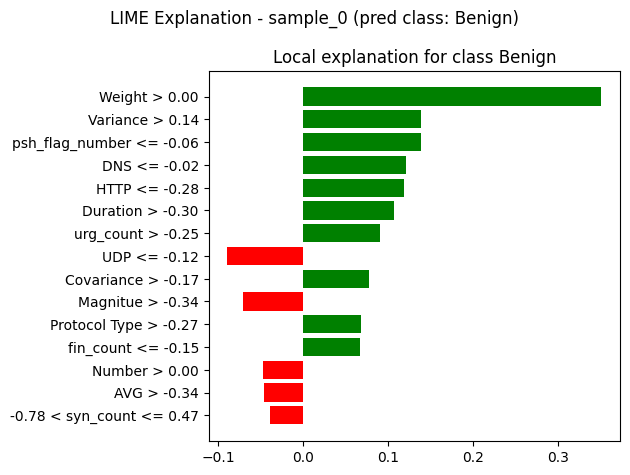

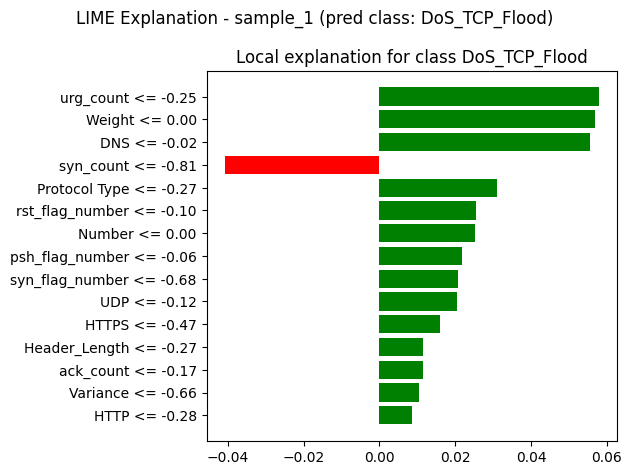

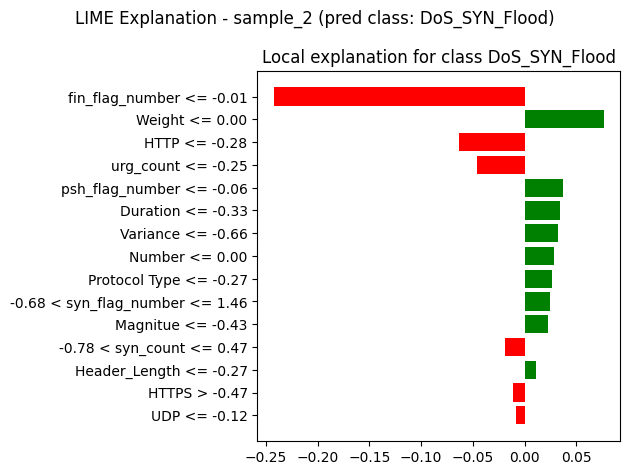

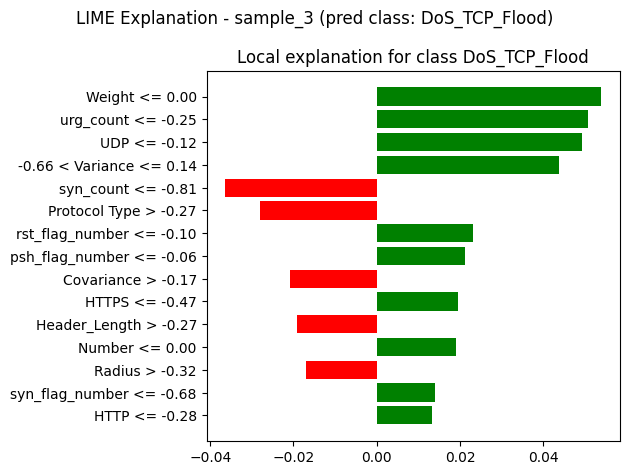

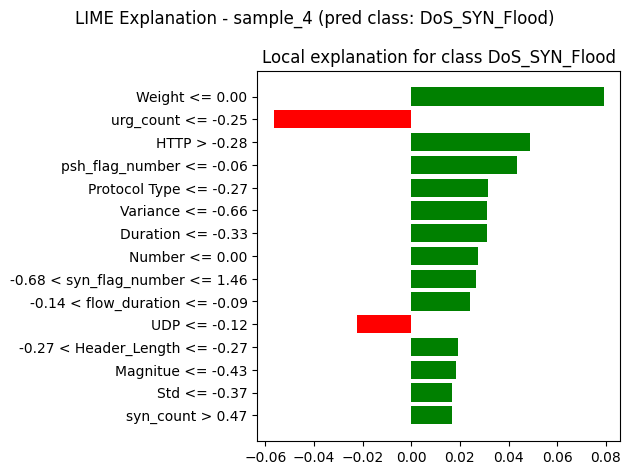

In [42]:
from lime.lime_tabular import LimeTabularExplainer
from sklearn.utils import check_random_state

# Ensure 2D arrays
X_train_2d = X_train[:, :, 0] if X_train.ndim == 3 else X_train
X_test_2d  = X_test_final[:, :, 0] if X_test_final.ndim == 3 else X_test_final

lime_explainer = LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names,
    class_names=list(le.classes_),
    mode="classification",
    discretize_continuous=True
)

lime_k = 5
lime_num_features = 15

for i in range(lime_k):
    exp = lime_explainer.explain_instance(
        data_row=X_test_2d[i],
        predict_fn=lambda x: model_predict_proba_numpy(x, model, device, batch_size=512),
        num_features=lime_num_features,
        top_labels=1
    )

    label = exp.top_labels[0]
    fig = exp.as_pyplot_figure(label=label)
    fig.suptitle(f"LIME Explanation - sample_{i} (pred class: {le.classes_[label]})", fontsize=12)
    fig.tight_layout()

    out_path = os.path.join(save_dir, f"lime_sample_{i}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


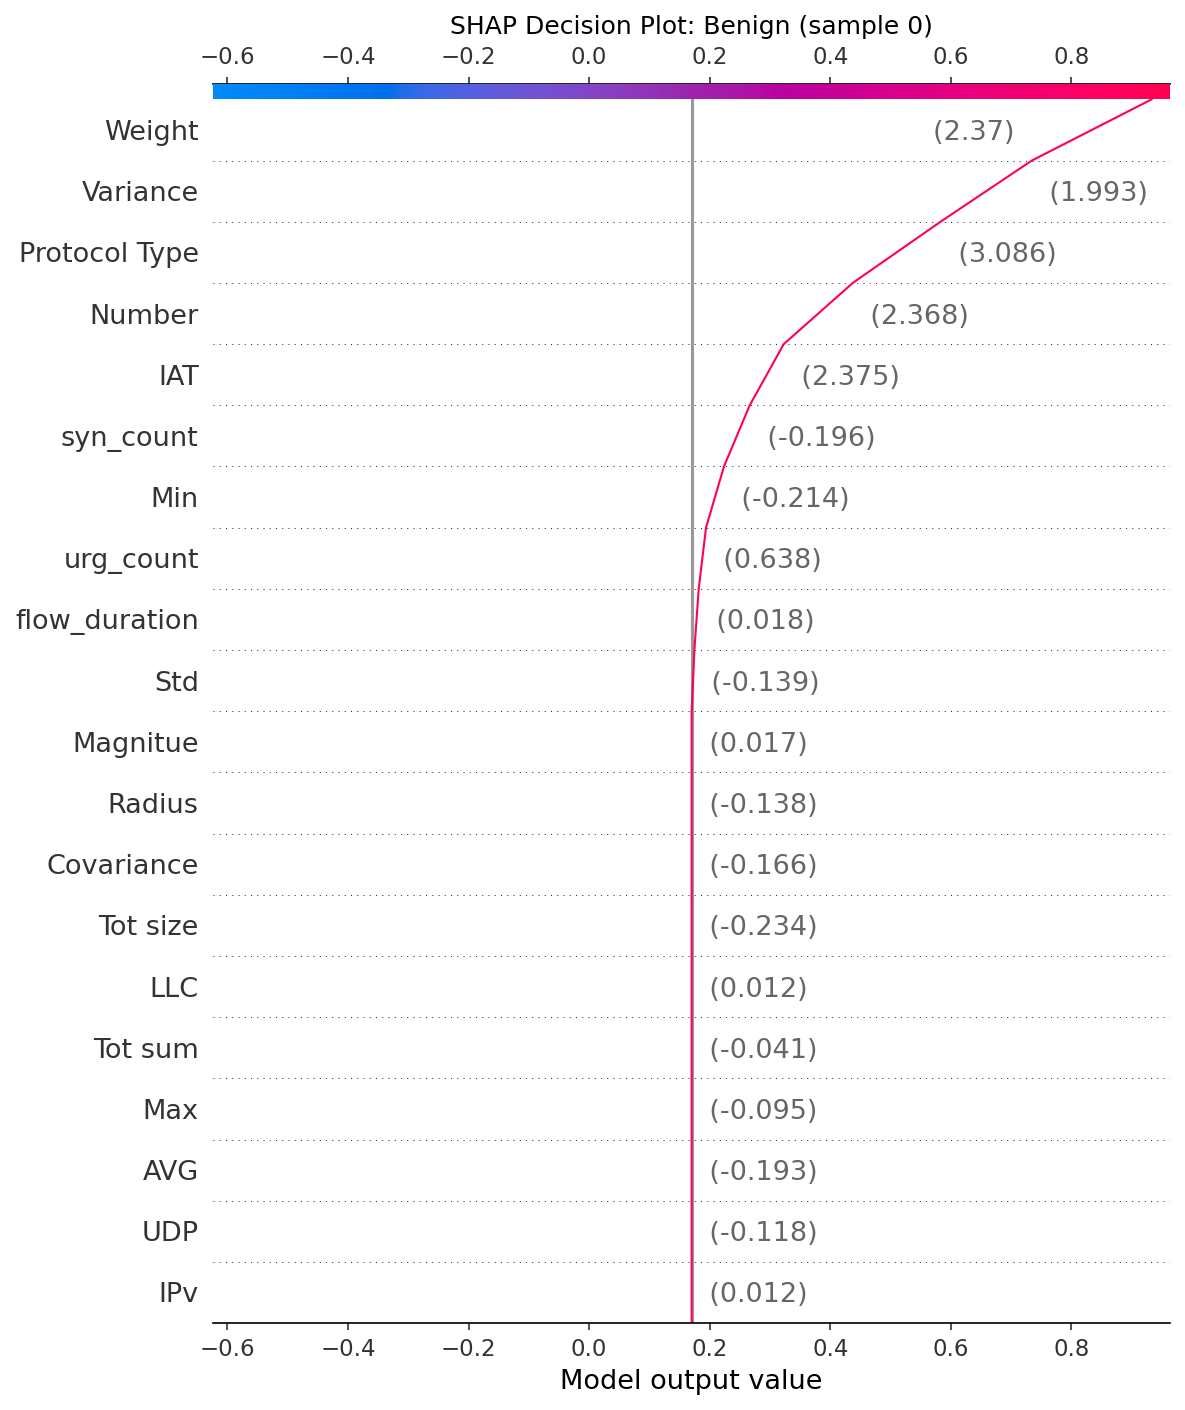

In [77]:
import os
import numpy as np
import matplotlib.pyplot as plt
import shap

os.makedirs(save_dir, exist_ok=True)

def shap_decision_plot_png(explainer, shap_values, X_data, feature_names, class_idx, sample_idx=0,
                           class_name=None, save_path=None):
    """
    shap_values: (N,F,C)
    X_data: (N,F)
    """
    sv = np.asarray(shap_values)
    X = np.asarray(X_data)
    assert sv.ndim == 3, f"Expected (N,F,C) got {sv.shape}"
    assert X.ndim == 2, f"Expected (N,F) got {X.shape}"

    # base_value for this class
    ev = explainer.expected_value
    if isinstance(ev, (list, tuple, np.ndarray)) and len(np.atleast_1d(ev)) > 1:
        base_value = np.atleast_1d(ev)[class_idx]
    else:
        base_value = float(np.atleast_1d(ev)[0])

    # SHAP values for ONE sample, ONE class => (F,)
    sv_sample = sv[sample_idx, :, class_idx]
    x_sample  = X[sample_idx, :]

    plt.figure(figsize=(12, 5), dpi=150)
    shap.decision_plot(
        base_value=base_value,
        shap_values=sv_sample,
        features=x_sample,
        feature_names=feature_names,
        show=False
    )

    if class_name is None:
        class_name = f"class_{class_idx}"

    plt.title(f"SHAP Decision Plot: {class_name} (sample {sample_idx})")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, f"shap_decision_{class_name}_sample_{sample_idx}.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# Example:
class_idx = 0
class_name = le.classes_[class_idx]
shap_decision_plot_png(
    explainer=explainer,
    shap_values=shap_values,
    X_data=X_shap_eval,
    feature_names=feature_names,
    class_idx=class_idx,
    sample_idx=0,
    class_name=class_name
)


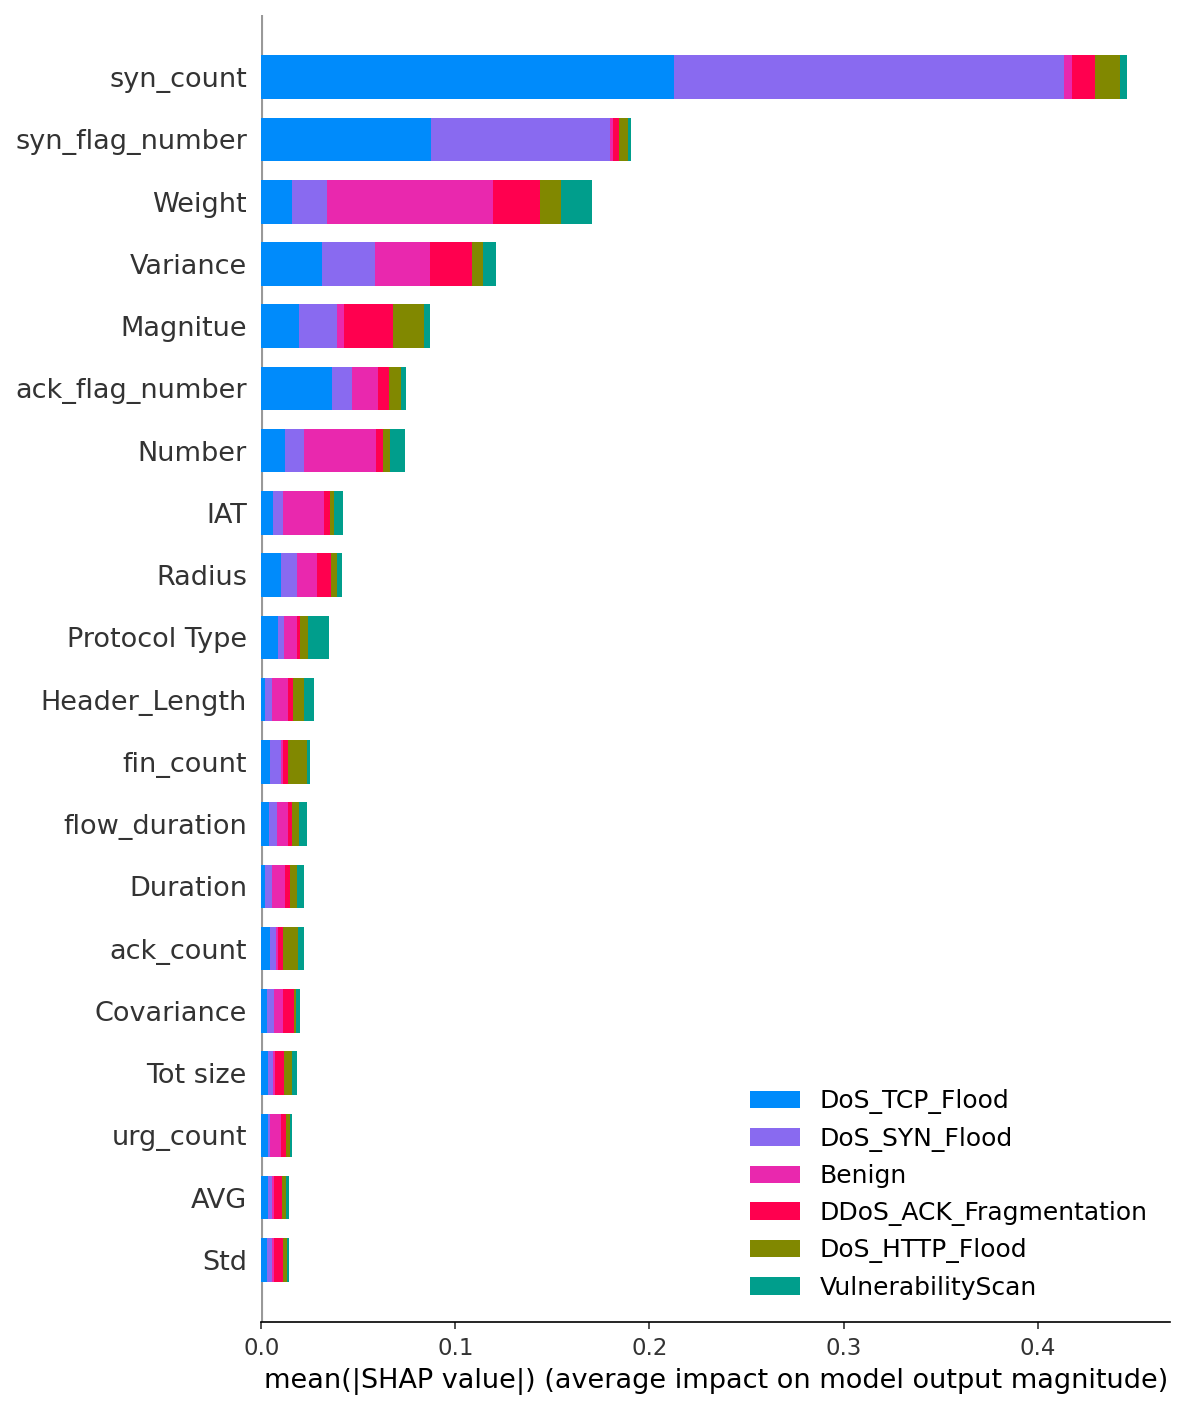

In [78]:
import os
import matplotlib.pyplot as plt
import shap
import numpy as np

def shap_multiclass_bar_summary_png(shap_values, X_data, feature_names, class_names, max_display=20, save_path=None):
    """
    Creates multi-class stacked bar plot of mean(|SHAP|) per feature.
    shap_values: (N,F,C)
    """
    sv = np.asarray(shap_values)
    X = np.asarray(X_data)

    plt.figure(figsize=(9, 11), dpi=150)
    shap.summary_plot(
        sv, X,
        feature_names=feature_names,
        class_names=class_names,
        plot_type="bar",
        max_display=max_display,
        show=False
    )
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "shap_multiclass_bar_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# Example:
shap_multiclass_bar_summary_png(
    shap_values=shap_values,
    X_data=X_shap_eval,
    feature_names=feature_names,
    class_names=list(le.classes_),
    max_display=20
)


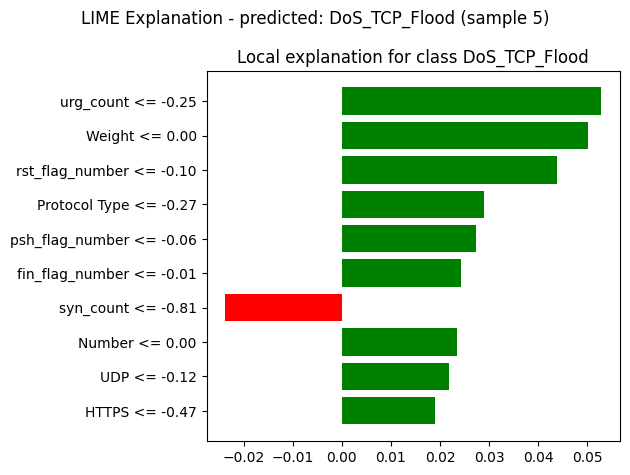

In [80]:
import os
import numpy as np
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

def lime_png_for_sample(X_train_2d, X_test_2d, feature_names, class_names,
                        model, device, sample_idx=0, num_features=10, save_path=None):

    lime_explainer = LimeTabularExplainer(
        training_data=X_train_2d,
        feature_names=feature_names,
        class_names=class_names,
        mode="classification",
        discretize_continuous=True
    )

    exp = lime_explainer.explain_instance(
        data_row=X_test_2d[sample_idx],
        predict_fn=lambda x: model_predict_proba_numpy(x, model, device, batch_size=512),
        num_features=num_features,
        top_labels=1
    )

    label = exp.top_labels[0]
    pred_name = class_names[label]

    fig = exp.as_pyplot_figure(label=label)
    fig.suptitle(f"LIME Explanation - predicted: {pred_name} (sample {sample_idx})", fontsize=12)
    fig.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, f"lime_explanation_{pred_name}_sample_{sample_idx}.png")

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Example (ensure 2D):
X_train_2d = X_train[:, :, 0] if X_train.ndim == 3 else X_train
X_test_2d  = X_test_final[:, :, 0] if X_test_final.ndim == 3 else X_test_final

lime_png_for_sample(
    X_train_2d=X_train_2d,
    X_test_2d=X_test_2d,
    feature_names=feature_names,
    class_names=list(le.classes_),
    model=model,
    device=device,
    sample_idx=5,
    num_features=10
)


In [88]:
import dice_ml
from dice_ml import Dice


In [89]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def counterfactual_summary_png(dice_exp, query_instance_df, feature_names, save_path=None):
    """
    Summarize DiCE counterfactual results:
    For each target class, compute the top feature change (delta) from the original query instance.
    Plot bar chart similar to your screenshot.
    """
    # original values (1-row DF)
    x0 = query_instance_df.iloc[0][feature_names].astype(float)

    rows = []

    # DiCE structure: dice_exp.cf_examples_list is a list, one per desired class
    for cf_ex in dice_exp.cf_examples_list:
        target_class = str(cf_ex.desired_class)  # sometimes 'opposite' etc.
        # The CF dataframe is in final_cfs_df
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue

        # Use the first CF (or average across CFs)
        cf1 = cf_df.iloc[0][feature_names].astype(float)

        deltas = (cf1 - x0)
        # pick top absolute change
        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        rows.append({"Target Class": target_class, "Top Feature": top_feat, "Delta": top_delta})

    if len(rows) == 0:
        print("No counterfactuals found to summarize.")
        return None

    df_sum = pd.DataFrame(rows)

    # Plot
    plt.figure(figsize=(14, 6), dpi=150)
    bars = plt.bar(df_sum["Target Class"], df_sum["Delta"])
    plt.axhline(0, linewidth=1)

    # annotate top feature name above each bar (vertical like your screenshot)
    for b, feat in zip(bars, df_sum["Top Feature"]):
        x = b.get_x() + b.get_width()/2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title("Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "counterfactual_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    return df_sum

# Example usage:
# query_instance_df must be a 1-row DF with the SAME columns/features used in DiCE
# df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)


In [91]:
# Convert train data back to 2D if needed
X_train_2d = X_train[:, :, 0] if X_train.ndim == 3 else X_train

df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names)
df_train_dice["label"] = le.inverse_transform(y_train)


In [92]:
dice_data = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names,
    outcome_name="label"
)


In [93]:
def dice_predict(X):
    probs = model_predict_proba_numpy(X, model, device)
    return probs

dice_model = dice_ml.Model(
    model=dice_predict,
    backend="PYT",
    model_type="classifier"
)


In [94]:
exp_dice = Dice(dice_data, dice_model, method="random")


In [96]:
# Convert to 2D if needed
X_test_2d = X_test_final[:, :, 0] if X_test_final.ndim == 3 else X_test_final

# Choose sample index
sample_idx = 0

# Create query dataframe
query_instance_df = pd.DataFrame(
    [X_test_2d[sample_idx]],
    columns=feature_names
)

query_instance_df.head()


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight
0,0.017507,-0.225301,3.086016,0.07021,-0.049248,-0.049248,0.0,-0.00856,-0.684796,-0.104447,...,-0.193069,-0.138624,-0.233928,2.374977,2.368441,0.01659,-0.137752,-0.166006,1.992836,2.369778


In [98]:
# dice_exp = exp_dice.generate_counterfactuals(
#     query_instance_df,
#     total_CFs=3,
#     desired_class=target_class
# )


dice_exp = exp_dice.generate_counterfactuals(
    query_instance_df,
    total_CFs=8,
    desired_class="opposite"
)



  0%|          | 0/1 [00:00<?, ?it/s]


AttributeError: 'numpy.ndarray' object has no attribute 'float'

In [84]:
# query_instance_df must be a 1-row DF with the SAME columns/features used in DiCE
df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)


NameError: name 'dice_exp' is not defined

In [100]:
# ============================================================
# COPY-PASTE: DiCE Counterfactuals (works with your PyTorch model)
# Fixes: exp_dice / dice_exp / query_instance_df / target_class errors
# Output: dice_exp + optional counterfactual summary PNG
# ============================================================

import os
import numpy as np
import pandas as pd
import dice_ml
from dice_ml import Dice

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

# ----------------------------
# 0) Helpers
# ----------------------------
def to_2d(X):
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

def model_predict_proba_numpy(X_2d, model, device, batch_size=512):
    """
    Returns probabilities (N, C) from your PyTorch model.
    Assumes model input shape should be (N, F, 1).
    """
    import torch
    model.eval()
    X_2d = np.asarray(X_2d, dtype=np.float32)
    probs_all = []

    with torch.no_grad():
        for i in range(0, len(X_2d), batch_size):
            xb = X_2d[i:i+batch_size]
            xb_t = torch.tensor(xb, dtype=torch.float32, device=device).unsqueeze(-1)  # (N,F,1)
            logits = model(xb_t)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs_all.append(probs)

    return np.vstack(probs_all)

# ----------------------------
# 1) Build DiCE "Data" object
# ----------------------------
X_train_2d = to_2d(X_train)  # (N,F)
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names)
df_train_dice["label"] = le.inverse_transform(y_train)  # y_train is encoded ints

dice_data = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names,
    outcome_name="label"
)

# ----------------------------
# 2) Wrap PyTorch model as sklearn-like predict_proba
# ----------------------------
class SklearnLikeWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values
        return model_predict_proba_numpy(X, self.model, self.device, batch_size=512)

wrapped_model = SklearnLikeWrapper(model, device)

dice_model = dice_ml.Model(
    model=wrapped_model,
    backend="sklearn",        # IMPORTANT: use sklearn backend with predict_proba
    model_type="classifier"
)

# ----------------------------
# 3) Create DiCE explainer
# ----------------------------
exp_dice = Dice(dice_data, dice_model, method="random")

# ----------------------------
# 4) Create query_instance_df (1 row) and generate counterfactuals
# ----------------------------
X_test_2d = to_2d(X_test_final)

sample_idx = 0  # change this to any index you want
query_instance_df = pd.DataFrame([X_test_2d[sample_idx]], columns=feature_names)

dice_exp = exp_dice.generate_counterfactuals(
    query_instance_df,
    total_CFs=8,
    desired_class="opposite"  # simplest: flip the prediction
)

# Show counterfactuals as a dataframe (in notebook)
dice_exp.visualize_as_dataframe()

# ----------------------------
# 5) OPTIONAL: Counterfactual Summary PNG (top delta feature per CF target)
# ----------------------------
import matplotlib.pyplot as plt

def counterfactual_summary_png(dice_exp, query_instance_df, feature_names, save_path=None):
    x0 = query_instance_df.iloc[0][feature_names].astype(float)

    rows = []
    for cf_ex in dice_exp.cf_examples_list:
        target_class = str(cf_ex.desired_class)
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue

        cf1 = cf_df.iloc[0][feature_names].astype(float)
        deltas = (cf1 - x0)

        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        rows.append({"Target Class": target_class, "Top Feature": top_feat, "Delta": top_delta})

    if len(rows) == 0:
        print("No counterfactuals found to summarize.")
        return None

    df_sum = pd.DataFrame(rows)

    plt.figure(figsize=(14, 6), dpi=150)
    bars = plt.bar(df_sum["Target Class"], df_sum["Delta"])
    plt.axhline(0, linewidth=1)

    for b, feat in zip(bars, df_sum["Top Feature"]):
        x = b.get_x() + b.get_width() / 2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title("Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "counterfactual_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)
    return df_sum

df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)
df_cf_summary

  0%|          | 0/1 [00:00<?, ?it/s]


UserConfigValidationException: The target class for random could not be identified

In [101]:
# ============================================================
# COPY-PASTE: DiCE Counterfactuals for MULTI-CLASS (6 classes)
# - Fixes: desired_class="opposite" not allowed for multi-class
# - Auto-selects a different target class than current prediction
# - Works with your PyTorch model using sklearn backend wrapper
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dice_ml
from dice_ml import Dice

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

# ----------------------------
# 0) Helpers
# ----------------------------
def to_2d(X):
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

def model_predict_proba_numpy(X_2d, model, device, batch_size=512):
    import torch
    model.eval()
    X_2d = np.asarray(X_2d, dtype=np.float32)
    probs_all = []

    with torch.no_grad():
        for i in range(0, len(X_2d), batch_size):
            xb = X_2d[i:i+batch_size]
            xb_t = torch.tensor(xb, dtype=torch.float32, device=device).unsqueeze(-1)  # (N,F,1)
            logits = model(xb_t)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs_all.append(probs)

    return np.vstack(probs_all)

# ----------------------------
# 1) Build DiCE "Data" object
# ----------------------------
X_train_2d = to_2d(X_train)  # (N,F)

df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names)
df_train_dice["label"] = le.inverse_transform(y_train)  # y_train: encoded ints

dice_data = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names,
    outcome_name="label"
)

# ----------------------------
# 2) Wrap PyTorch model as sklearn-like predict_proba
# ----------------------------
class SklearnLikeWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values
        return model_predict_proba_numpy(X, self.model, self.device, batch_size=512)

wrapped_model = SklearnLikeWrapper(model, device)

dice_model = dice_ml.Model(
    model=wrapped_model,
    backend="sklearn",
    model_type="classifier"
)

# ----------------------------
# 3) Create DiCE explainer
# ----------------------------
exp_dice = Dice(dice_data, dice_model, method="random")

# ----------------------------
# 4) Create query instance
# ----------------------------
X_test_2d = to_2d(X_test_final)
sample_idx = 0  # change this if you want

query_instance_df = pd.DataFrame([X_test_2d[sample_idx]], columns=feature_names)

# ----------------------------
# 5) Pick a valid multi-class target (NOT "opposite")
#    Choose second-best class by probability (different from predicted)
# ----------------------------
probs = wrapped_model.predict_proba(query_instance_df)  # shape (1,C)
pred_idx = int(np.argmax(probs[0]))
sorted_idx = np.argsort(probs[0])[::-1]

# pick the best class that is NOT the predicted one
target_idx = int(sorted_idx[1]) if len(sorted_idx) > 1 else pred_idx
target_class = le.classes_[target_idx]

print("Predicted class:", le.classes_[pred_idx], "prob:", probs[0][pred_idx])
print("Target class   :", target_class, "prob:", probs[0][target_idx])

# ----------------------------
# 6) Generate counterfactuals for that target class
# ----------------------------
dice_exp = exp_dice.generate_counterfactuals(
    query_instance_df,
    total_CFs=8,
    desired_class=target_class
)

# Show counterfactuals in notebook
dice_exp.visualize_as_dataframe()

# ----------------------------
# 7) Counterfactual Summary PNG
# ----------------------------
def counterfactual_summary_png(dice_exp, query_instance_df, feature_names, save_path=None):
    x0 = query_instance_df.iloc[0][feature_names].astype(float)

    rows = []
    for cf_ex in dice_exp.cf_examples_list:
        target = str(cf_ex.desired_class)
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue

        cf1 = cf_df.iloc[0][feature_names].astype(float)
        deltas = (cf1 - x0)

        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        rows.append({"Target Class": target, "Top Feature": top_feat, "Delta": top_delta})

    if len(rows) == 0:
        print("No counterfactuals found to summarize.")
        return None

    df_sum = pd.DataFrame(rows)

    plt.figure(figsize=(14, 6), dpi=150)
    bars = plt.bar(df_sum["Target Class"], df_sum["Delta"])
    plt.axhline(0, linewidth=1)

    for b, feat in zip(bars, df_sum["Top Feature"]):
        x = b.get_x() + b.get_width() / 2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title("Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "counterfactual_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)
    return df_sum

df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)
df_cf_summary


Predicted class: Benign prob: 0.93309045
Target class   : DoS_TCP_Flood prob: 0.015317676


  0%|          | 0/1 [00:00<?, ?it/s]


UserConfigValidationException: The target class for DoS_TCP_Flood could not be identified

In [102]:
# ============================================================
# COPY-PASTE (UPDATED): DiCE Counterfactuals for MULTI-CLASS PyTorch
# Fix: add wrapper.classes_ so DiCE can map desired_class strings
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dice_ml
from dice_ml import Dice

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

# ----------------------------
# 0) Helpers
# ----------------------------
def to_2d(X):
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

def model_predict_proba_numpy(X_2d, model, device, batch_size=512):
    import torch
    model.eval()
    X_2d = np.asarray(X_2d, dtype=np.float32)
    probs_all = []

    with torch.no_grad():
        for i in range(0, len(X_2d), batch_size):
            xb = X_2d[i:i+batch_size]
            xb_t = torch.tensor(xb, dtype=torch.float32, device=device).unsqueeze(-1)  # (N,F,1)
            logits = model(xb_t)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs_all.append(probs)

    return np.vstack(probs_all)

# ----------------------------
# 1) Build DiCE Data object
# ----------------------------
X_train_2d = to_2d(X_train)
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names)
df_train_dice["label"] = le.inverse_transform(y_train)

dice_data = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names,
    outcome_name="label"
)

# ----------------------------
# 2) Wrapper with classes_ (CRITICAL)
# ----------------------------
class SklearnLikeWrapper:
    """
    DiCE expects sklearn-like model with:
      - predict_proba(X) -> (N,C)
      - classes_ attribute matching columns of predict_proba
    """
    def __init__(self, model, device, class_names):
        self.model = model
        self.device = device
        self.classes_ = np.array(class_names, dtype=object)  # IMPORTANT

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values
        return model_predict_proba_numpy(X, self.model, self.device, batch_size=512)

    def predict(self, X):
        probs = self.predict_proba(X)
        idx = np.argmax(probs, axis=1)
        return self.classes_[idx]

wrapped_model = SklearnLikeWrapper(model, device, class_names=list(le.classes_))

dice_model = dice_ml.Model(
    model=wrapped_model,
    backend="sklearn",
    model_type="classifier"
)

# ----------------------------
# 3) Create DiCE explainer
# ----------------------------
exp_dice = Dice(dice_data, dice_model, method="random")

# ----------------------------
# 4) Query instance
# ----------------------------
X_test_2d = to_2d(X_test_final)
sample_idx = 0
query_instance_df = pd.DataFrame([X_test_2d[sample_idx]], columns=feature_names)

# ----------------------------
# 5) Pick a valid target class (different from predicted)
# ----------------------------
probs = wrapped_model.predict_proba(query_instance_df)  # (1,C)
pred_idx = int(np.argmax(probs[0]))
sorted_idx = np.argsort(probs[0])[::-1]
target_idx = int(sorted_idx[1])  # 2nd best class
target_class = wrapped_model.classes_[target_idx]  # string label

print("Predicted class:", wrapped_model.classes_[pred_idx], "prob:", float(probs[0][pred_idx]))
print("Target class   :", target_class, "prob:", float(probs[0][target_idx]))

# ----------------------------
# 6) Generate counterfactuals (MULTI-CLASS)
# ----------------------------
dice_exp = exp_dice.generate_counterfactuals(
    query_instance_df,
    total_CFs=8,
    desired_class=str(target_class),   # now DiCE can map it
    verbose=True
)

dice_exp.visualize_as_dataframe()

# ----------------------------
# 7) Counterfactual Summary PNG
# ----------------------------
def counterfactual_summary_png(dice_exp, query_instance_df, feature_names, save_path=None):
    x0 = query_instance_df.iloc[0][feature_names].astype(float)

    rows = []
    for cf_ex in dice_exp.cf_examples_list:
        target = str(cf_ex.desired_class)
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue

        cf1 = cf_df.iloc[0][feature_names].astype(float)
        deltas = (cf1 - x0)

        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        rows.append({"Target Class": target, "Top Feature": top_feat, "Delta": top_delta})

    if len(rows) == 0:
        print("No counterfactuals found to summarize.")
        return None

    df_sum = pd.DataFrame(rows)

    plt.figure(figsize=(14, 6), dpi=150)
    bars = plt.bar(df_sum["Target Class"], df_sum["Delta"])
    plt.axhline(0, linewidth=1)

    for b, feat in zip(bars, df_sum["Top Feature"]):
        x = b.get_x() + b.get_width() / 2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title("Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "counterfactual_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)
    return df_sum

df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)
df_cf_summary


Predicted class: Benign prob: 0.9330904483795166
Target class   : DoS_TCP_Flood prob: 0.015317675657570362


  0%|          | 0/1 [00:00<?, ?it/s]


UserConfigValidationException: The target class for DoS_TCP_Flood could not be identified

In [103]:
print("In DiCE data labels:", sorted(df_train_dice["label"].unique())[:20])
print("In le.classes_     :", list(le.classes_))


In DiCE data labels: ['Benign', 'DDoS_ACK_Fragmentation', 'DoS_HTTP_Flood', 'DoS_SYN_Flood', 'DoS_TCP_Flood', 'VulnerabilityScan']
In le.classes_     : ['Benign', 'DDoS_ACK_Fragmentation', 'DoS_HTTP_Flood', 'DoS_SYN_Flood', 'DoS_TCP_Flood', 'VulnerabilityScan']


Predicted class: DoS_SYN_Flood prob: 0.9300013184547424
Target class   : DoS_TCP_Flood prob: 0.016830673441290855


100%|██████████| 1/1 [01:12<00:00, 72.45s/it]

Diverse Counterfactuals found! total time taken: 01 min 12 sec
Query instance (original outcome : DoS_SYN_Flood)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,-0.121147,-0.26806,-0.266679,-0.332132,-0.049342,-0.049342,0.0,-0.00856,1.460289,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_SYN_Flood



Diverse Counterfactual set (new outcome: DoS_TCP_Flood)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,-0.121147,-0.26806,-0.266679,-0.332132,-0.049342,-0.049342,0.0,-0.00856,1.460289,1.025389,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_TCP_Flood
1,-0.121147,-0.26806,-0.266679,2.556274,-0.049342,-0.049342,0.0,-0.00856,-0.569475,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_TCP_Flood
2,-0.121147,-0.26806,-0.266679,4.075888,-0.049342,-0.049342,0.0,-0.00856,-0.495331,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.157414,0.000445,DoS_TCP_Flood
3,-0.121147,-0.26806,-0.266679,-0.332132,-0.049342,-0.049342,0.0,-0.00856,1.460289,1.025389,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_TCP_Flood
4,-0.121147,-0.26806,-0.266679,4.075888,-0.049342,-0.049342,0.1,-0.00856,-0.495331,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.157414,0.000445,DoS_TCP_Flood
5,-0.121147,-0.26806,-0.266679,2.556274,-0.049342,-0.049342,0.0,-0.00856,-0.569475,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_TCP_Flood
6,-0.121147,-0.26806,-0.266679,2.556274,-0.049342,-0.049342,0.0,-0.00856,-0.569475,-0.104447,...,-0.374593,-0.374547,-0.001744,0.000461,-0.43221,-0.374166,-0.173553,-0.657309,0.000445,DoS_TCP_Flood


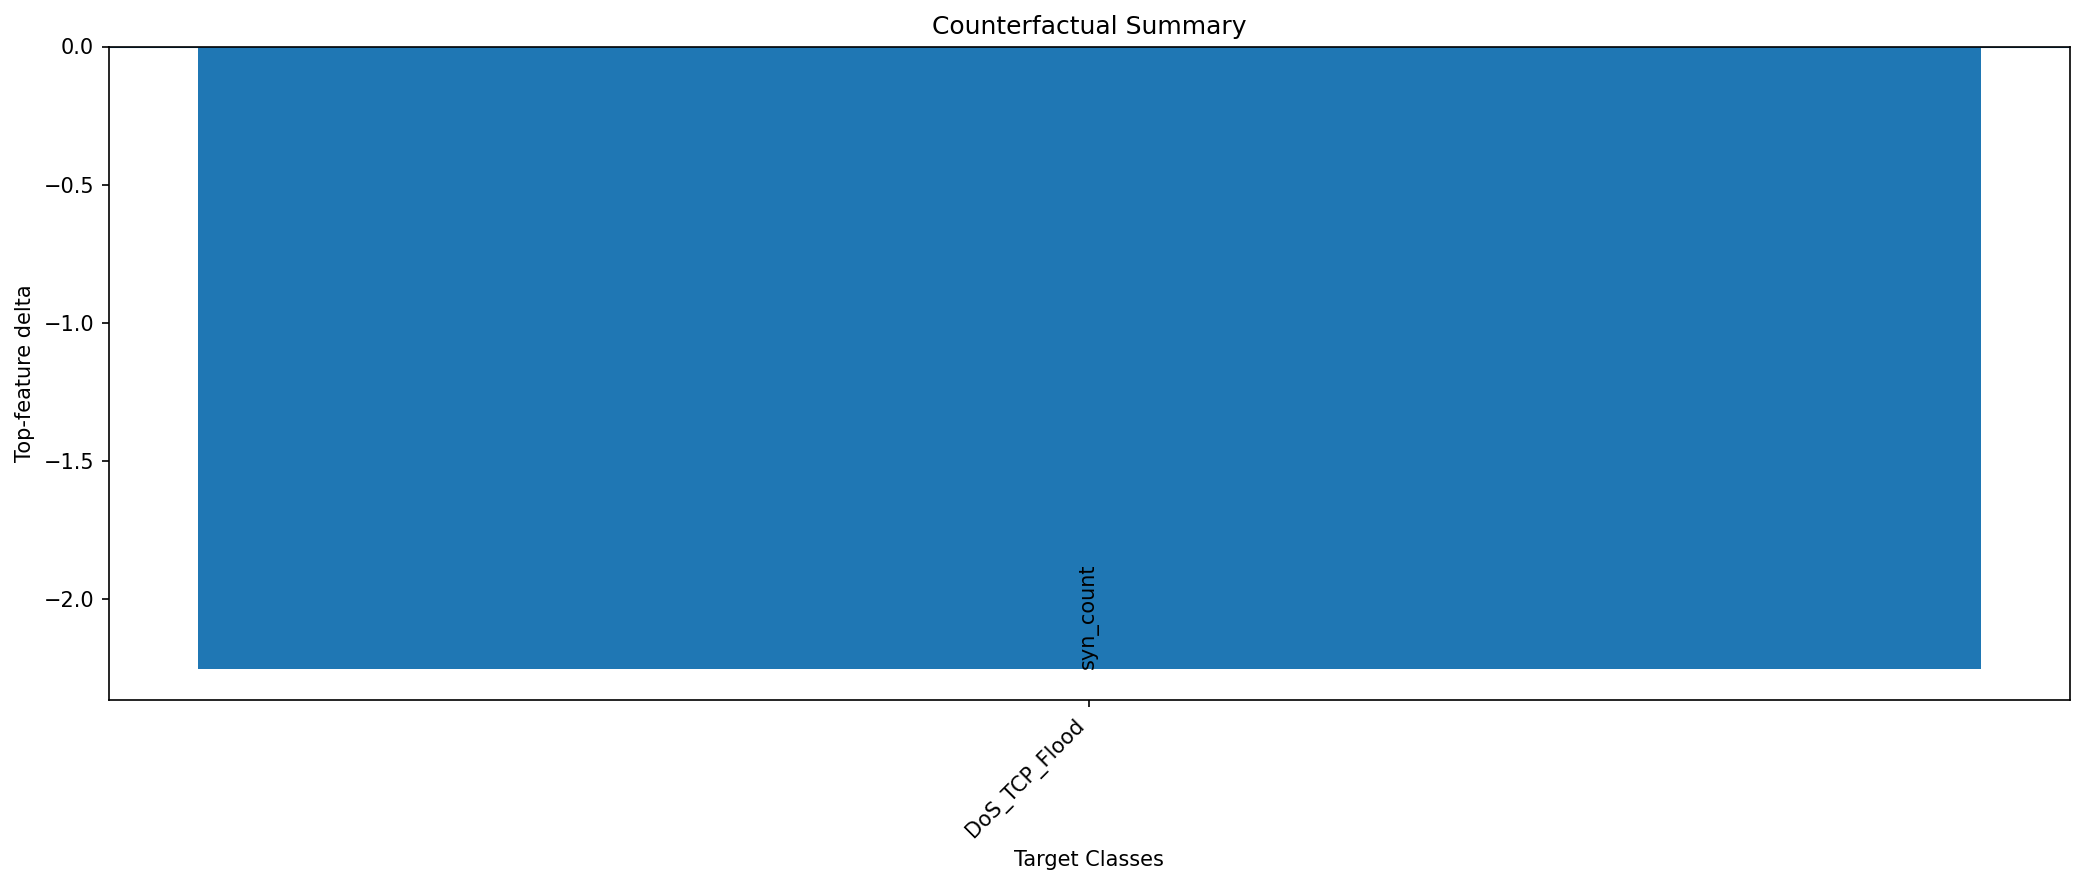

Saved: xai_outputs/counterfactual_summary.png


,Target Class,Top Feature,Delta
0,DoS_TCP_Flood,syn_count,-2.255371


In [105]:
# ============================================================
# COPY-PASTE (ROBUST): DiCE Counterfactuals for MULTI-CLASS PyTorch
# - Uses desired_class as INTEGER index (most reliable)
# - Ensures predict_proba returns float64
# - Ensures classes_ is a Python list of strings
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dice_ml
from dice_ml import Dice

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

# ----------------------------
# 0) Helpers
# ----------------------------
def to_2d(X):
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

def model_predict_proba_numpy(X_2d, model, device, batch_size=512):
    import torch
    model.eval()
    X_2d = np.asarray(X_2d, dtype=np.float32)
    probs_all = []

    with torch.no_grad():
        for i in range(0, len(X_2d), batch_size):
            xb = X_2d[i:i+batch_size]
            xb_t = torch.tensor(xb, dtype=torch.float32, device=device).unsqueeze(-1)  # (N,F,1)
            logits = model(xb_t)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probs_all.append(probs)

    return np.vstack(probs_all)

# ----------------------------
# 1) Build DiCE Data object
# ----------------------------
X_train_2d = to_2d(X_train)
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names)
df_train_dice["label"] = le.inverse_transform(y_train)

dice_data = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names,
    outcome_name="label"
)

# ----------------------------
# 2) Wrapper model for DiCE (sklearn backend)
# ----------------------------
class SklearnLikeWrapper:
    def __init__(self, model, device, class_names):
        self.model = model
        self.device = device
        # IMPORTANT: python list of strings
        self.classes_ = [str(c) for c in class_names]

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values
        probs = model_predict_proba_numpy(X, self.model, self.device, batch_size=512)
        return probs.astype(np.float64)  # DiCE sometimes expects float64

    def predict(self, X):
        probs = self.predict_proba(X)
        idx = np.argmax(probs, axis=1)
        return np.array([self.classes_[i] for i in idx], dtype=object)

wrapped_model = SklearnLikeWrapper(model, device, class_names=list(le.classes_))

dice_model = dice_ml.Model(
    model=wrapped_model,
    backend="sklearn",
    model_type="classifier"
)

# ----------------------------
# 3) Create DiCE explainer
# ----------------------------
exp_dice = Dice(dice_data, dice_model, method="random")

# ----------------------------
# 4) Query instance
# ----------------------------
X_test_2d = to_2d(X_test_final)
sample_idx = 8
query_instance_df = pd.DataFrame([X_test_2d[sample_idx]], columns=feature_names)

# ----------------------------
# 5) Pick target class index (2nd best class)
# ----------------------------
probs = wrapped_model.predict_proba(query_instance_df)  # (1,C)
pred_idx = int(np.argmax(probs[0]))
sorted_idx = np.argsort(probs[0])[::-1]
target_idx = int(sorted_idx[1])  # 2nd best index

print("Predicted class:", wrapped_model.classes_[pred_idx], "prob:", float(probs[0][pred_idx]))
print("Target class   :", wrapped_model.classes_[target_idx], "prob:", float(probs[0][target_idx]))

# ----------------------------
# 6) Generate counterfactuals (use desired_class as INT index)
# ----------------------------
dice_exp = exp_dice.generate_counterfactuals(
    query_instance_df,
    total_CFs=8,
    desired_class=target_idx,     # <-- MOST ROBUST
    verbose=True
)

dice_exp.visualize_as_dataframe()

# ----------------------------
# 7) Counterfactual Summary PNG
# ----------------------------
def counterfactual_summary_png(dice_exp, query_instance_df, feature_names, save_path=None):
    x0 = query_instance_df.iloc[0][feature_names].astype(float)

    rows = []
    for cf_ex in dice_exp.cf_examples_list:
        target = str(cf_ex.desired_class)
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            continue

        cf1 = cf_df.iloc[0][feature_names].astype(float)
        deltas = (cf1 - x0)

        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        rows.append({"Target Class": target, "Top Feature": top_feat, "Delta": top_delta})

    if len(rows) == 0:
        print("No counterfactuals found to summarize.")
        return None

    df_sum = pd.DataFrame(rows)

    plt.figure(figsize=(14, 6), dpi=150)
    bars = plt.bar(df_sum["Target Class"], df_sum["Delta"])
    plt.axhline(0, linewidth=1)

    for b, feat in zip(bars, df_sum["Top Feature"]):
        x = b.get_x() + b.get_width() / 2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title("Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if save_path is None:
        save_path = os.path.join(save_dir, "counterfactual_summary.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)
    return df_sum

df_cf_summary = counterfactual_summary_png(dice_exp, query_instance_df, feature_names)
df_cf_summary


Predicted: Benign prob: 0.9330904483795166


100%|██████████| 1/1 [00:07<00:00,  7.81s/it]


[OK] DDoS_ACK_Fragmentation: top=Max, delta=14.7754


100%|██████████| 1/1 [00:29<00:00, 29.70s/it]


[OK] DoS_HTTP_Flood: top=Tot sum, delta=11.2375


...

[OK] DoS_SYN_Flood: top=fin_count, delta=110.5414


100%|██████████| 1/1 [00:01<00:00,  1.97s/it]


No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 01 sec
[SKIP] DoS_TCP_Flood: No counterfactuals found for any of the query points! Kindly check your configuration.


100%|██████████| 1/1 [00:08<00:00,  8.07s/it]


[OK] VulnerabilityScan: top=Weight, delta=-3.1818
             Target Class Top Feature       Delta
0  DDoS_ACK_Fragmentation         Max   14.775396
1          DoS_HTTP_Flood     Tot sum   11.237464
2           DoS_SYN_Flood   fin_count  110.541395
3       VulnerabilityScan      Weight   -3.181806


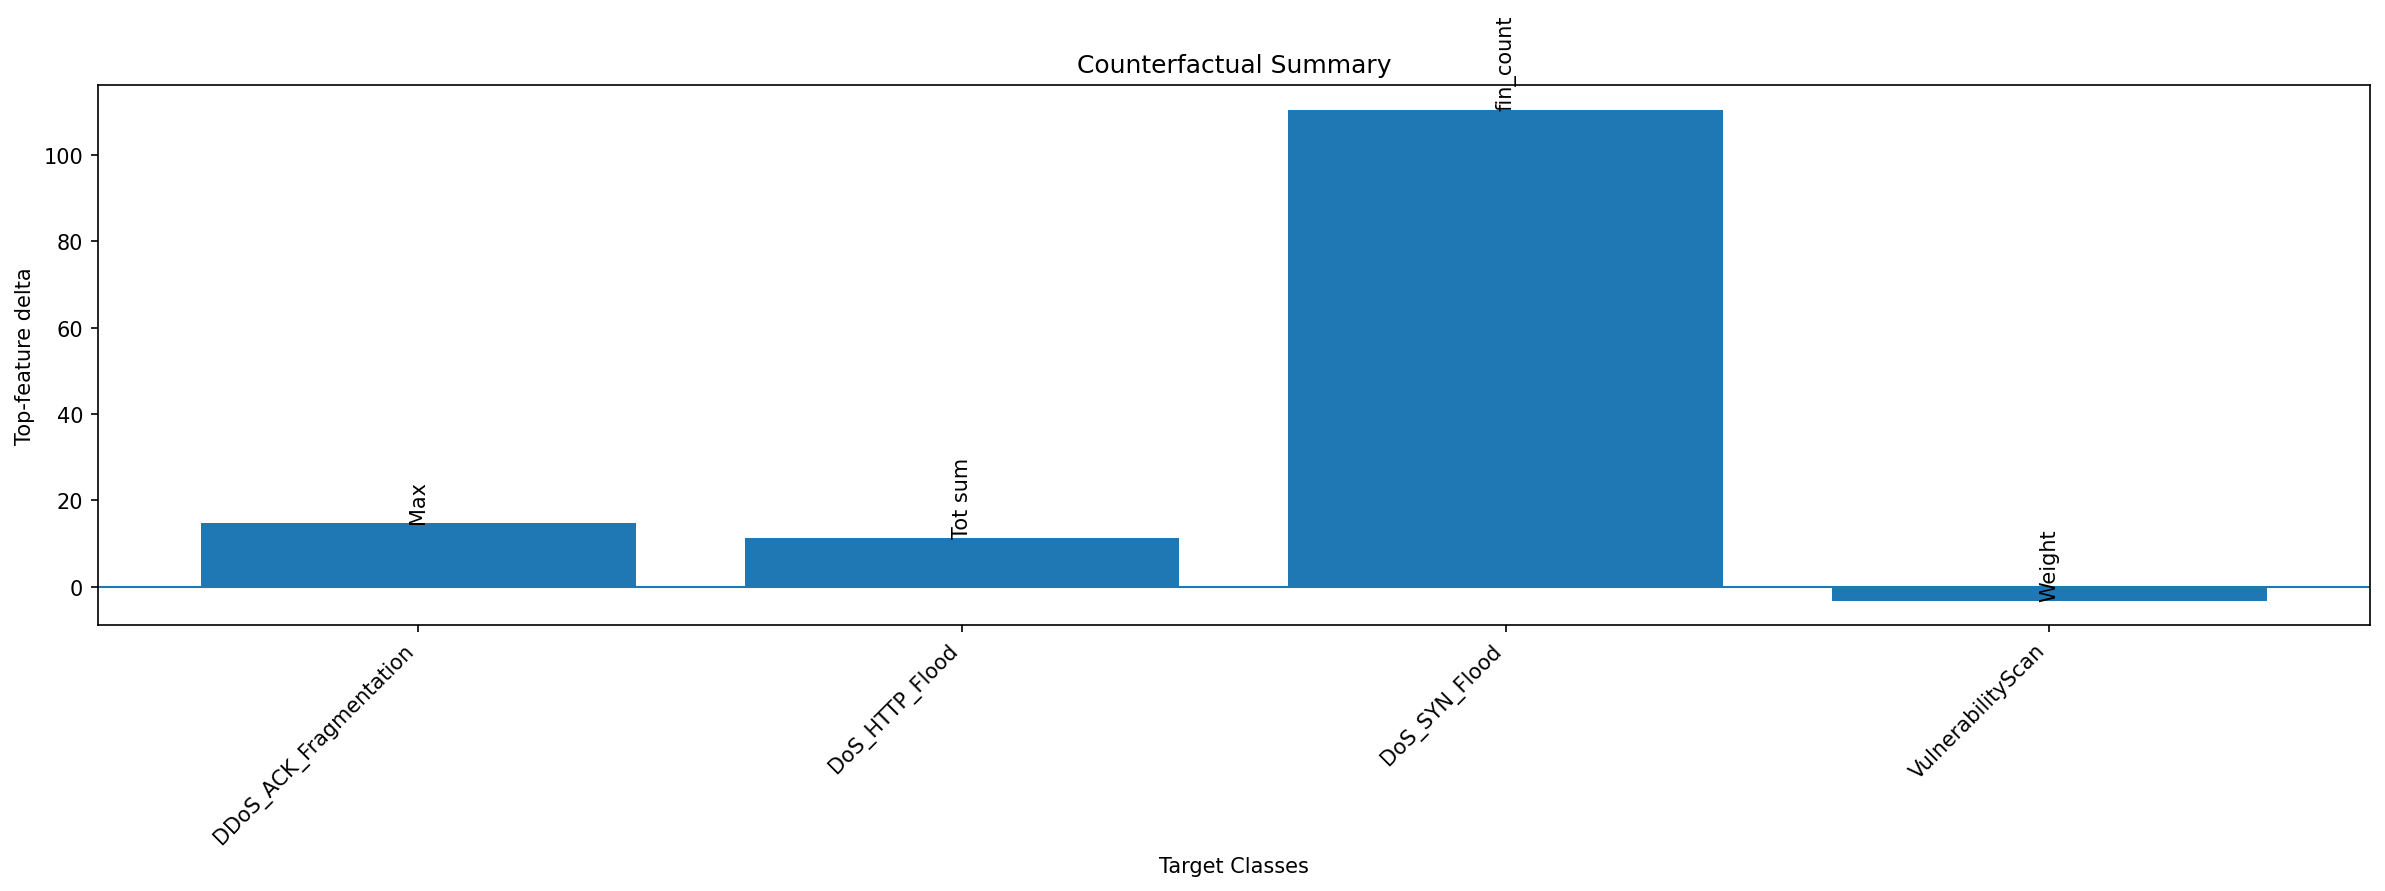

Saved: xai_outputs/counterfactual_summary_all_classes_sample_0.png


In [108]:
# ============================================================
# FIXED: Counterfactual Summary for EVERY class (multi-class)
# Key fix: use desired_class as INT index (0..C-1), not string
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("xai_outputs", exist_ok=True)
save_dir = "xai_outputs"

def to_2d(X):
    X = np.asarray(X)
    if X.ndim == 3 and X.shape[-1] == 1:
        return X[:, :, 0]
    return X

# ---- Make query instance ----
X_test_2d = to_2d(X_test_final)
sample_idx = 0
query_instance_df = pd.DataFrame([X_test_2d[sample_idx]], columns=feature_names)

# ---- Predicted class ----
probs = wrapped_model.predict_proba(query_instance_df)  # (1,C)
pred_idx = int(np.argmax(probs[0]))
print("Predicted:", le.classes_[pred_idx], "prob:", float(probs[0][pred_idx]))

# ============================================================
# Generate CF for each target class (by index)
# ============================================================
results = []
num_classes = len(le.classes_)

for target_idx in range(num_classes):
    if target_idx == pred_idx:
        continue

    target_name = le.classes_[target_idx]
    try:
        dice_exp = exp_dice.generate_counterfactuals(
            query_instance_df,
            total_CFs=8,
            desired_class=int(target_idx),  # <<< IMPORTANT FIX
            verbose=False
        )

        # Pull first CF
        cf_ex = dice_exp.cf_examples_list[0]
        cf_df = cf_ex.final_cfs_df
        if cf_df is None or len(cf_df) == 0:
            print(f"[NO CF] {target_name}")
            continue

        x0 = query_instance_df.iloc[0][feature_names].astype(float)
        cf1 = cf_df.iloc[0][feature_names].astype(float)

        deltas = (cf1 - x0)
        top_feat = deltas.abs().sort_values(ascending=False).index[0]
        top_delta = float(deltas[top_feat])

        results.append({
            "Target Class": str(target_name),
            "Top Feature": str(top_feat),
            "Delta": top_delta
        })

        print(f"[OK] {target_name}: top={top_feat}, delta={top_delta:.4f}")

    except Exception as e:
        print(f"[SKIP] {target_name}: {e}")

df_cf_summary_all = pd.DataFrame(results)
print(df_cf_summary_all)

# ============================================================
# Plot ONE chart (bars for every target class)
# ============================================================
if len(df_cf_summary_all) == 0:
    print("No counterfactuals generated for any class.")
else:
    plt.figure(figsize=(16, 6), dpi=150)
    bars = plt.bar(df_cf_summary_all["Target Class"], df_cf_summary_all["Delta"])
    plt.axhline(0, linewidth=1)

    for b, feat in zip(bars, df_cf_summary_all["Top Feature"]):
        x = b.get_x() + b.get_width() / 2
        y = b.get_height()
        plt.text(x, y, feat, ha="center", va="bottom", rotation=90, fontsize=10)

    plt.title(f"Counterfactual Summary")
    plt.ylabel("Top-feature delta")
    plt.xlabel("Target Classes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    out_path = os.path.join(save_dir, f"counterfactual_summary_all_classes_sample_{sample_idx}.png")
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", out_path)


In [ ]:
import os
import imgkit
from lime.lime_tabular import LimeTabularExplainer

# (Assuming explainer_lime is already initialized)

num_lime_samples = min(5, len(X_explain))

for i in range(num_lime_samples):
    print(f"Generating LIME explanation for sample {i}...")
    
    # Generate explanation
    exp = explainer_lime.explain_instance(
        data_row=X_explain[i],
        predict_fn=lambda x: model_predict_proba_numpy(x, model, device),
        num_features=10
    )
    
    html_file = os.path.join(save_dir, f"lime_sample_{i}.html")
    png_filename = os.path.join(save_dir, f"lime_sample_{i}_imgkit.png")
    
    # Save the HTML file
    exp.save_to_file(html_file)
    
    # Convert HTML directly to PNG using imgkit
    # We pass an empty dict to options or specific wkhtmltoimage flags if needed
    imgkit.from_file(html_file, png_filename, options={'format': 'png', 'quiet': ''})
    
    print(f"Saved LIME PNG to {png_filename}")

In [63]:
import torch
import torch.nn.functional as F

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Hooks to grab activations and gradients
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, x_tensor, target_class):
        self.model.eval()
        self.model.zero_grad()
        
        # Forward pass
        logits = self.model(x_tensor)
        score = logits[:, target_class].sum()
        
        # Backward pass
        score.backward()
        
        # Pool gradients (dim 2 for 1D CNNs)
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2])
        
        # Weight activations by gradients
        activations = self.activations.detach().clone()
        for i in range(activations.shape[1]):
            activations[:, i, :] *= pooled_gradients[i]
            
        # Average across channels and apply ReLU
        heatmap = torch.mean(activations, dim=1).squeeze()
        heatmap = F.relu(heatmap)
        
        # Normalize
        if torch.max(heatmap) > 0:
            heatmap /= torch.max(heatmap)
            
        return heatmap.cpu().numpy()

# --- Run Grad-CAM ---
# ⚠️ REPLACE `model.layer1` with your actual final Conv1D layer!
target_layer = model.layer1  

grad_cam = GradCAM1D(model, target_layer)

for i in range(min(5, len(X_explain))):
    # Shape needs to be (1, Features, 1) for your model
    x_tensor = torch.tensor(X_explain[i:i+1], dtype=torch.float32, device=device).unsqueeze(-1)
    x_tensor.requires_grad_()
    
    with torch.no_grad():
        logits = model(x_tensor)
        pred_class = torch.argmax(logits, dim=1).item()
    
    # Generate Heatmap
    heatmap = grad_cam.generate(x_tensor, target_class=pred_class)
    
    # Plotting
    plt.figure(figsize=(10, 2))
    plt.imshow(heatmap[np.newaxis, :], aspect='auto', cmap='jet')
    plt.xticks(ticks=np.arange(len(feature_names)), labels=feature_names, rotation=90)
    plt.yticks([])
    plt.colorbar(label='Importance')
    plt.title(f"Grad-CAM - Sample {i} (Predicted Class: {class_names[pred_class]})")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"gradcam_sample_{i}.png"), dpi=300, bbox_inches="tight")
    plt.close()

print("Grad-CAM generation complete.")

AttributeError: 'CNNTransformerBiLSTM' object has no attribute 'layer1'

In [66]:
!apt-get update
!apt-get install -y wkhtmltopdf
!pip install imgkit

Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease     
Hit:3 https://cli.github.com/packages stable InRelease                         
Hit:4 http://security.ubuntu.com/ubuntu jammy-security InRelease               
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease                         
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease                 
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease               
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois